# Mechanism-Based Intelligence (MBI) Framework: Empirical Validation

Appendix C provides the empirical proof-of-concept for the Mechanism-Based Intelligence (MBI) framework, moving beyond theoretical guarantees to numerical validation. Using simulations, MBI is systematically tested across 12 distinct scenarios, examining its fidelity, scalability, efficiency and robustness in decentralized environments. The results support MBI as a solution for optimal resource allocation and global welfare maximization, compared to uncoordinated decentralized baselines.

## Tests Implementation and Mechanism Fidelity

Tests are implemented in Python using libraries like PyTorch and NumPy that utilize full vectorization to efficiently compute the collective loss and the incentive signal $\mathbf{G}_i$ of the Differentiable Price Mechanism (DPM) for all $N$ agents in parallel. Automatic differentiation computes the signal exactly, up to floating-point precision. The simulations obtain $\mathbf{G}_i = -\nabla_{\mathbf{x}_i}\mathcal{L}_{\text{global}}$; since each cost $C_i$ depends only on $\mathbf{x}_i$, this equals the Planner's price $-\nabla_{\mathbf{x}_i}\mathcal{L}_{\text{system}}$ plus the agent's own marginal cost, so the trajectories are those of the mechanism of Appendix B, in which the Planner knows no private costs (B.1.1). The exception is the part of C.6 in which the Planner prices an agent's cost itself with an estimate $\hat{\lambda}_i$, which illustrates Theorem 3 (Part 2). Each section reports the step size $\eta$, which satisfies the condition $0 < \eta < 2/L_{\nabla}$ of Theorem 4 for its loss, except where C.5 exceeds it deliberately to test the stability bound.

Sections C.1 to C.11 use system losses in which agents interact through the sum of their outputs; C.12 tests pricing through a compositional Differentiable Directed Acyclic Graph (D-DAG).

## Summary Table: MBI Empirical Validation (C.1 through C.12)

| Category | Sections | Summary of Results |
| :--- | :--- | :--- |
| **I. Mechanism Fidelity** | C.1, C.2, C.3, C.12 | With costless effort, agents converge to the global optimum to numerical precision: two agents (C.1, $\lVert \mathbf{x} - \mathbf{x}^* \rVert \approx 10^{-12}$), $N = 100$ symmetrical agents (C.2, loss gap $1.4 \times 10^{-17}$) and five heterogeneous producers in a stylized economic dispatch (C.3), where the DPM price equalizes all marginal costs. MBI's loss is $9.1$ (C.2), $1.6$ (C.3) and $1.4$ (C.12) times lower than the free-rider Nash equilibrium. In a D-DAG, backpropagation reproduces the chain-rule price exactly and agents converge to the optimum (C.12). |
| **II. Benchmark and Scale** | C.4, C.11 | On a known, differentiable loss, MBI reaches a loss of $0.0020$ after $120$ gradient evaluations, against $0.0200 \pm 0.0072$ for PPO after $1,920$ loss evaluations (single-state task, untuned PPO; C.4). The cost per iteration grows close to linearly in $N$ up to $10^7$ agents (fitted exponent $1.093$), while for summed losses the iterations to converge grow roughly in proportion to $N$ (C.11). |
| **III. Convergence, Stability and Bounded Rationality** | C.1, C.5, C.8, C.9 | Gradient steps converge for every $\eta < 2/L_{\nabla}$ and diverge above it, with a sharp boundary at $\pm 1\%$ (C.5). Satisficing agents stop within the residual bound (B.14) (C.1), and the stopping rule (B.13) selects the effort level that minimizes total cost, up to one discrete step (C.9). In a non-convex landscape, MBI converges to a local minimum that is $45\%$ better than free-riding but $62\%$ above the global minimum, which $5\%$ of random starts reach (C.8). |
| **IV. Information and Robustness** | C.6, C.7, C.10 | The Planner needs no knowledge of private costs: its belief does not affect the outcome (C.6, Theorem 3 Part 1). If the Planner prices costs itself, a $10\%$ error in all costs raises the loss by $0.001\%$, a misestimated single cost by $33\%$, and pricing with the expected cost minimizes the expected loss (C.6, Part 2). Under persistent action noise the dynamics remain stable, with a stationary excess loss matching its closed form $\approx N\sigma^2/(4\eta)$ (C.7). A private, time-varying cost unknown to the Planner is internalized: actions track the moving optimum of the true cost (C.10). |

In [1]:
# ==============================================================================
# MBI Reproducibility Notebook Setup and Universal Functions
# ==============================================================================

# --- IMPORT REQUIRED LIBRARIES ---
import torch
import torch.optim as optim
import numpy as np
from scipy.optimize import minimize
from typing import Dict, Any, List, Union, Tuple, Optional
import matplotlib.pyplot as plt
import random
import os
import timeit
import time

# ==============================================================================
# --- UNIVERSAL ANALYTICAL & PRINTING HELPERS ---
# ==============================================================================

def get_parallel_analytical_optimum(N: int, Y_star: float, lam: float) -> float:
    r"""
    Calculates the optimal action ($\mathbf{x}^*$) for the N-symmetrical parallel system.

    This result is derived by finding the global minimum of the loss function:
    $$\mathcal{L} = \left(\sum_{i=1}^{N} x_i - Y^*\right)^2 + \sum_{i=1}^{N} \lambda \mathbf{x}_i^2$$
    and solving for the symmetrical optimum $\mathbf{x}_i = \mathbf{x}^*$.

    Parameters
    ----------
    N : int
        The total number of agents in the system.
    Y_star : float
        The global target output ($Y^*$).
    lam : float
        The symmetrical cost penalty coefficient ($\lambda$).

    Returns
    -------
    float
        The optimal individual action $\mathbf{x}^*$ that minimizes the global loss.
        (Analytically: $\mathbf{x}^* = \frac{Y^*}{N + \lambda}$)
    """
    # Analytical solution for the global optimum (MBI convergence point)
    return Y_star / (N + lam)

def get_parallel_nash_benchmark(N: int, Y_star: float, lam: float) -> Dict[str, float]:
    r"""
    Calculates the uncoordinated Nash equilibrium without DPM transfers and its global loss.

    Free-rider benchmark: each agent i bears its own cost and only its 1/N share of the
    system loss, minimizing
    $$\frac{1}{N}\left(\sum_{j=1}^{N} x_j - Y^*\right)^2 + \lambda \mathbf{x}_i^2$$
    while taking the other agents' actions as given. This differs from the MBI outcome,
    which is the Nash equilibrium of the game induced by the DPM transfers (Theorem 1).

    Parameters
    ----------
    N : int
        The total number of agents in the system.
    Y_star : float
        The global target output ($Y^*$).
    lam : float
        The symmetrical cost penalty coefficient ($\lambda$).

    Returns
    -------
    Dict[str, float]
        A dictionary containing the uncoordinated equilibrium action ('x_ne') and the
        resulting total loss ('L_ne').
        (Analytically: $\mathbf{x}_{ne} = \frac{Y^*}{N(1 + \lambda)}$)
    """
    # Symmetric uncoordinated equilibrium: x_ne = Y* / (N (1 + lambda))
    x_ne = Y_star / (N * (1.0 + lam))

    # Global Loss (L_ne) resulting from the uncoordinated actions
    L_ne = (N * x_ne - Y_star) ** 2 + N * lam * x_ne ** 2

    return {'x_ne': x_ne, 'L_ne': L_ne}

def get_fully_heterogeneous_targets(Y_star: float, lambda_dict: Dict[str, float]) -> Dict[str, float]:
    r"""
    Calculates optimal actions ($\mathbf{x}^*$) and Loss ($\mathcal{L}^*$) for a fully heterogeneous system.

    This applies to systems where each agent has a unique cost coefficient ($\lambda_i$),
    but a common output goal ($Y^*$).

    Parameters
    ----------
    Y_star : float
        The global target output ($Y^*$).
    lambda_dict : Dict[str, float]
        A dictionary mapping agent names to their individual cost coefficients ($\lambda_i$).

    Returns
    -------
    Dict[str, float]
        A dictionary containing the optimal action for each agent, plus the
        resulting optimal total loss ('L_opt') and the sum of optimal actions ('Sum_x_opt').
    """
    # Calculate the sum of inverse lambda values (sum(1/lambda_i))
    sum_inv_lambda = sum(1.0 / lam for lam in lambda_dict.values())

    # K is the constant multiplier in the denominator
    K = 1.0 + sum_inv_lambda

    x_opt = {}
    for agent, lam in lambda_dict.items():
        # Optimal action for agent i: x_i* = Y* / (lambda_i * K)
        x_opt[agent] = Y_star / (lam * K)

    # Optimal Global Loss: L* = Y*^2 / K
    L_opt = (Y_star * Y_star) / K

    x_opt['L_opt'] = L_opt
    x_opt['Sum_x_opt'] = sum(x_opt[agent] for agent in lambda_dict.keys())

    return x_opt

def get_heterogeneous_nash_benchmark(Y_star: float, lambda_dict: Dict[str, float]) -> Dict[str, float]:
    r"""
    Uncoordinated Nash equilibrium without DPM transfers for a fully heterogeneous system
    (free-rider benchmark): each agent i minimizes its own cost plus its 1/N share of the
    system loss,
    $$\frac{1}{N}\left(\sum_{j} x_j - Y^*\right)^2 + \lambda_i \mathbf{x}_i^2,$$
    taking the other agents' actions as given.
    
    Solution: $\mathbf{x}_i^{NE} = \frac{Y^*}{N \lambda_i (1 + s)}$ with $s = \frac{1}{N}\sum_j 1/\lambda_j$.
    Reduces to get_parallel_nash_benchmark when all lambda_i are equal.
    
    Returns
    -------
    Dict[str, float]
        The equilibrium action of each agent, plus 'Sum_x_ne' and 'L_ne'.
    """
    N = len(lambda_dict)
    s = sum(1.0 / lam for lam in lambda_dict.values()) / N
    ne = {agent: Y_star / (N * lam * (1.0 + s)) for agent, lam in lambda_dict.items()}
    sum_x = sum(ne.values())
    ne['Sum_x_ne'] = sum_x
    ne['L_ne'] = (sum_x - Y_star) ** 2 + sum(lambda_dict[a] * ne[a] ** 2 for a in lambda_dict)
    return ne

# ==============================================================================
# --- UNIVERSAL PLOTTING HELPERS ---
# ==============================================================================

def plot_convergence_trajectory(
    history: Dict[str, List[float]],
    x_opt: Dict[str, float],
    title: str,
    save_path: Optional[str] = None
):
    r"""
    Generates and displays a high-quality convergence plot for MBI simulations.

    The function dynamically adjusts the plot layout based on the input history keys,
    handling both single-axis parallel convergence (C.2, C.3) and multi-axis
    sequential convergence (C.1).

    Parameters
    ----------
    history : Dict[str, List[float]]
        A dictionary containing time series data from the simulation run.
        Expected keys for Parallel plots: ['loss', 'x_mean', 'x_std'].
        Expected keys for Sequential plots: ['loss', 'x1', 'x2'].
    x_opt : Dict[str, float]
        A dictionary containing the analytical optimal targets for verification.
        Expected keys include 'L_opt' and optimal action keys like 'x_mean_opt' or 'x1_opt'.
    title : str
        The main title for the figure.
    save_path : str, optional
        File path to save the resulting figure (e.g., 'fig_c2.png'). If None,
        the plot is displayed but not saved (default is None).

    Notes
    -----
    Uses 'seaborn-v0_8-whitegrid' style for high contrast.
    In parallel mode, the first START_ITER iterations are omitted from the plot;
    figure captions should state this.
    """

    # Define plot style
    plt.style.use('seaborn-v0_8-whitegrid')
    colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7']

    # --- Determine Plot Range for Stability ---
    # Skip the first few iterations to avoid log-scale jitter near startup and improve clarity
    START_ITER = 5
    total_iterations = len(history.get('loss', []))
    x_range = range(START_ITER, total_iterations)

    # --- Parallel Plotting Mode (C.2, C.3) ---
    if 'x_mean' in history and total_iterations > START_ITER:
        fig, ax = plt.subplots(2, 1, figsize=(7, 7), constrained_layout=True)
        # Determine the correct optimal mean action target
        if 'x_mean_opt' in x_opt:
            x_mean_target = x_opt['x_mean_opt']
        elif 'x1_opt' in x_opt:
            x_mean_target = x_opt['x1_opt']
        else:
            raise ValueError("x_opt must contain 'x_mean_opt' or 'x1_opt' for the target line.")

        # Plot 0: Global Loss Convergence (Log Scale)
        loss_history = history['loss'][START_ITER:]
        ax[0].plot(x_range, loss_history, color=colors[0], label='Simulated Loss')
        ax[0].set_ylabel(r'Loss ($\mathcal{L}$)')
        ax[0].set_title('Global Loss Convergence (Log Scale)')

        if x_opt.get('L_opt', None) is not None:
            ax[0].axhline(x_opt['L_opt'], linestyle=':', color='gray', alpha=0.8,
                          label=r'Target $\mathcal{L}^*$')
            ax[0].legend(loc='upper right', fontsize=8, frameon=True)

        ax[0].set_yscale('log', nonpositive='clip')
        ax[0].set_xlabel(r'Planner Iteration ($t$)')

        # Plot 1: Mean Action Convergence (bar_x)
        x_mean = np.array(history['x_mean'][START_ITER:])
        x_std = np.array(history['x_std'][START_ITER:])

        # Plot mean and fill between mean +/- standard deviation
        ax[1].plot(x_range, x_mean, color=colors[1], label=r'Mean Action $\bar{\mathbf{x}}$')
        ax[1].fill_between(x_range, x_mean - x_std, x_mean + x_std, color=colors[1], alpha=0.2)
        ax[1].axhline(x_mean_target, linestyle='--', color='r', alpha=0.8,
                      label=rf'Target $\bar{{x}}^*={x_mean_target:.4f}$')
        ax[1].set_xlabel(r'Planner Iteration ($t$)')
        ax[1].set_ylabel(r'Agent Action (Mean $\pm$ Std Dev)')
        ax[1].legend(loc='upper right', fontsize=8, frameon=True)

    # --- Sequential Plotting Mode (C.1) ---
    elif 'x1' in history:
        fig, ax = plt.subplots(3, 1, figsize=(7, 9), constrained_layout=True)
        if 'x1_opt' not in x_opt or 'x2_opt' not in x_opt:
            raise ValueError("x_opt must contain 'x1_opt' and 'x2_opt' for the target lines.")
        x1_target = x_opt['x1_opt']
        x2_target = x_opt['x2_opt']

        # Panel 0: Loss (Always log scale for MBI)
        ax[0].plot(history['loss'], color=colors[0], label='Simulated Loss')
        ax[0].set_ylabel(r'Loss ($\mathcal{L}$)')
        ax[0].set_title('Global Loss Convergence (Log Scale)')
        if x_opt.get('L_opt', None) is not None:
            ax[0].axhline(x_opt['L_opt'], linestyle=':', color='gray', alpha=0.8,
                          label=r'Target $\mathcal{L}^*$')
            ax[0].legend(loc='upper right', fontsize=8, frameon=True)
        ax[0].set_yscale('log', nonpositive='clip')
        ax[0].set_xlabel(r'Planner Iteration ($t$)')

        # Panel 1: Agent 1 Action
        ax[1].plot(history['x1'], color=colors[1])
        ax[1].axhline(x1_target, linestyle='--', color='r',
                      label=rf'Target $x_1^*={x1_target:.4f}$')
        ax[1].set_ylabel(r'Agent 1 Action ($\mathbf{x}_1$)')
        ax[1].legend(loc='upper right', fontsize=8, frameon=True)
        ax[1].set_xlabel(r'Planner Iteration ($t$)')

        # Panel 2: Agent 2 Action
        ax[2].plot(history['x2'], color=colors[2])
        ax[2].axhline(x2_target, linestyle='--', color='r',
                      label=rf'Target $x_2^*={x2_target:.4f}$')
        ax[2].set_ylabel(r'Agent 2 Action ($\mathbf{x}_2$)')
        ax[2].set_xlabel(r'Planner Iteration ($t$)')

        ax[2].legend(loc='upper right', fontsize=8, bbox_to_anchor=(1, 0.9), frameon=True)

    # --- Error/Fallback ---
    else:
        print("Error: History keys ('x1', 'x_mean') not found for plotting. Cannot determine plot type.")
        return

    # Finalization
    plt.suptitle(title, fontsize=14, fontweight='bold')
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()


# --- SET GLOBAL SEED FOR REPRODUCIBILITY ---

def set_global_seed(seed: int) -> None:
    """
    Sets a global seed across all relevant libraries (PyTorch, NumPy, random)
    and configures CUDA for deterministic operations to ensure full reproducibility.
    """
    # Standard Python seed
    random.seed(seed)

    # NumPy seed
    np.random.seed(seed)

    # PyTorch seeds (CPU and, where available, CUDA)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)  # For multi-GPU setups

        # CUDA/cuDNN settings for deterministic GPU operations
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

# Set global seed
set_global_seed(42)

## C.1 Numerical Validation: Incentive Compatibility (IC) and Bounded Rationality (BR)

### 1. Objective

To validate numerically that the decentralized actions of self-interested agents, governed by the DPM, converge to the Global Optimum ($\mathbf{x}^*$) when effort is costless, confirming IC (Theorem 1, Appendix B.3) and convergence (Theorem 4, Part 1, Appendix B.6). Simultaneously, to validate the BR Satisficing Condition (Theorem 2, Appendix B.4): when effort is costly, agents come to rest at a profile whose residual incentive satisfies the bound (B.14), and the gap to $\mathbf{x}^*$ shrinks as the marginal effort cost falls (Theorem 4, Part 2).

### 2. Methodology

The simulation operationalizes the two-agent D-DAG assembly line example provided in the manuscript. Agent $A_1$ (action $\mathbf{x}_1$) bears a private cost $\lambda \mathbf{x}_1^2$, while agent $A_2$ (action $\mathbf{x}_2$) refines the final output at no cost, creating a non-trivial dependency. Each agent's incentive $\mathbf{G}_i$ is the negative gradient of the global loss, the Planner's price plus the agent's own marginal cost.

* Global loss function:

$$\mathcal{L}_{\text{global}}(\mathbf{x}_1, \mathbf{x}_2) = (\mathbf{x}_1 + \mathbf{x}_2 - Y^*)^2 + \lambda \mathbf{x}_1^2 \tag{1}$$

* DPM:

$$\mathbf{G}_i = -\frac{\partial \mathcal{L}_{\text{global}}}{\partial \mathbf{x}_i} \tag{2}$$

* Dynamics (Theorem 4, Algorithm 1): both agents update simultaneously with a common step size $\eta$; agent $A_i$ takes the step $\mathbf{x}_i \leftarrow \mathbf{x}_i + \eta \mathbf{G}_i$ only if $\eta \mathbf{G}_i^2 > \frac{\partial \kappa}{\partial T}$, and otherwise satisfices. With $\frac{\partial \kappa}{\partial T} = 0$ the run stops when $\max_i |\mathbf{G}_i| < 10^{-12}$; with $\frac{\partial \kappa}{\partial T} > 0$ it stops when no agent updates.

| Parameter | Value |
| :--- | :--- |
| **Target ($Y^*$)** | $2.0$ |
| **Penalty ($\lambda$)** | $0.5$ |
| **Lipschitz constant ($L_{\nabla}$)** | $4.561553$ (largest Hessian eigenvalue) |
| **Step size ($\eta$)** | $0.2$, satisfying $\eta < 2/L_{\nabla} = 0.438447$ |
| **Marginal effort cost ($\frac{\partial \kappa}{\partial T}$)** | $0$, $10^{-2}$, $10^{-4}$, $10^{-6}$ |
| **Analytical Optimum** | $\mathbf{x}^* = (\mathbf{x}_1^*, \mathbf{x}_2^*) = (0.0, 2.0)$, $\mathcal{L}^* = 0$ |

Table C.1.1: Problem Parameters and Analytical Solution for the Two-Agent Assembly Line.

### 3. Key Metrics

| Metric | Target | Purpose of Measurement |
| :--- | :--- | :--- |
| **Final Global Loss ($\mathcal{L}$)** | $0.0$ when effort is costless | Measure of system efficiency (IC success). |
| **Final $\max_i |\mathbf{G}_i|$** | $\leq \sqrt{\frac{1}{\eta}\frac{\partial \kappa}{\partial T}}$ (B.14) | Test of **Satisficing/BR**. |
| **Distance $\|\mathbf{x} - \mathbf{x}^*\|$** | $0$ when effort is costless; shrinking as $\frac{\partial \kappa}{\partial T}$ falls | Test of **convergence** (Theorem 4). |
| **Mean Final Distance (50 Runs)** | as above | Test of **Robustness** across random initial conditions in $[-5, 5]^2$. |

### 4. Results

| $\frac{\partial \kappa}{\partial T}$ | Outcome | Iterations | Final $\mathcal{L}$ | Final $\max_i |\mathbf{G}_i|$ | Bound (B.14) | $\|\mathbf{x} - \mathbf{x}^*\|$ |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| $0$ | converged | 304 | $1.585\text{e-}24$ | $9.492\text{e-}13$ | n/a | $2.682\text{e-}12$ |
| $10^{-2}$ | at rest | 19 | $8.294\text{e-}02$ | $2.171\text{e-}01$ | $2.236\text{e-}01$ | $6.135\text{e-}01$ |
| $10^{-4}$ | at rest | 45 | $7.018\text{e-}04$ | $1.997\text{e-}02$ | $2.236\text{e-}02$ | $5.643\text{e-}02$ |
| $10^{-6}$ | at rest | 70 | $7.134\text{e-}06$ | $2.014\text{e-}03$ | $2.236\text{e-}03$ | $5.690\text{e-}03$ |

Table C.1.2: Validation of IC and BR for MBI Decentralized Convergence, single run from $\mathbf{x}(0) = (1, -1)$.

| $\frac{\partial \kappa}{\partial T}$ | Runs | Mean $\|\mathbf{x} - \mathbf{x}^*\|$ | Std. Dev. | Max | All residuals within (B.14) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| $0$ | 50 | $2.648\text{e-}12$ | $7.512\text{e-}14$ | $2.757\text{e-}12$ | n/a |
| $10^{-4}$ | 50 | $5.890\text{e-}02$ | $1.570\text{e-}03$ | $6.156\text{e-}02$ | yes |

Table C.1.3: Robustness across 50 random initial conditions in $[-5, 5]^2$.

Figure C.1 compares costless effort ($\partial\kappa/\partial T = 0$) with costly effort ($\partial\kappa/\partial T = 10^{-4}$): the global loss (log scale), the actions against their optimal values (costly case), and the residual incentive $\max_i |\mathbf{G}_i|$ against the bound (B.14). With costly effort, the agents come to rest after 45 iterations, just short of $\mathbf{x}^*$, with the residual incentive below the bound.

### 5. Conclusion

When effort is costless, the DPM drives the decentralized actions to the global optimum to numerical precision ($\|\mathbf{x} - \mathbf{x}^*\| \approx 10^{-12}$) from every initial condition tested, confirming IC (Theorem 1) and convergence (Theorem 4, Part 1). When effort is costly, agents satisfice: the process comes to rest after finitely many iterations at a profile where every agent's residual incentive lies within the bound (B.14), and the gap to $\mathbf{x}^*$ shrinks as the marginal effort cost falls, by roughly a factor of 10 for each factor-100 reduction, consistent with the $\sqrt{\partial \kappa / \partial T}$ scaling of (B.14) (Theorem 4, Part 2). The externality is internalized as predicted: the costly component $\mathbf{x}_1$ is suppressed and the zero-cost agent $A_2$ delivers the target output $Y^*$.



############################## RUNNING APPENDIX C.1 (TWO-AGENT IC/BR VALIDATION) ##############################

L_grad = 4.561553, 2/L_grad = 0.438447, eta = 0.2 (Theorem 4 condition satisfied)

Single run from x(0) = (1, -1):
  kappa' = 0        | converged (max|G_i| < 1e-12)     after    304 iterations | loss = 1.585e-24 | max|G_i| = 9.492e-13 (B.14 bound 0.000e+00) | ||x - x*|| = 2.682e-12
  kappa' = 0.01     | rest (no agent updates)          after     19 iterations | loss = 8.294e-02 | max|G_i| = 2.171e-01 (B.14 bound 2.236e-01) | ||x - x*|| = 6.135e-01
  kappa' = 0.0001   | rest (no agent updates)          after     45 iterations | loss = 7.018e-04 | max|G_i| = 1.997e-02 (B.14 bound 2.236e-02) | ||x - x*|| = 5.643e-02
  kappa' = 1e-06    | rest (no agent updates)          after     70 iterations | loss = 7.134e-06 | max|G_i| = 2.014e-03 (B.14 bound 2.236e-03) | ||x - x*|| = 5.690e-03

Robustness (random initial actions in [-5, 5]^2):
  kappa' = 0        | 50 runs | mean ||x - 

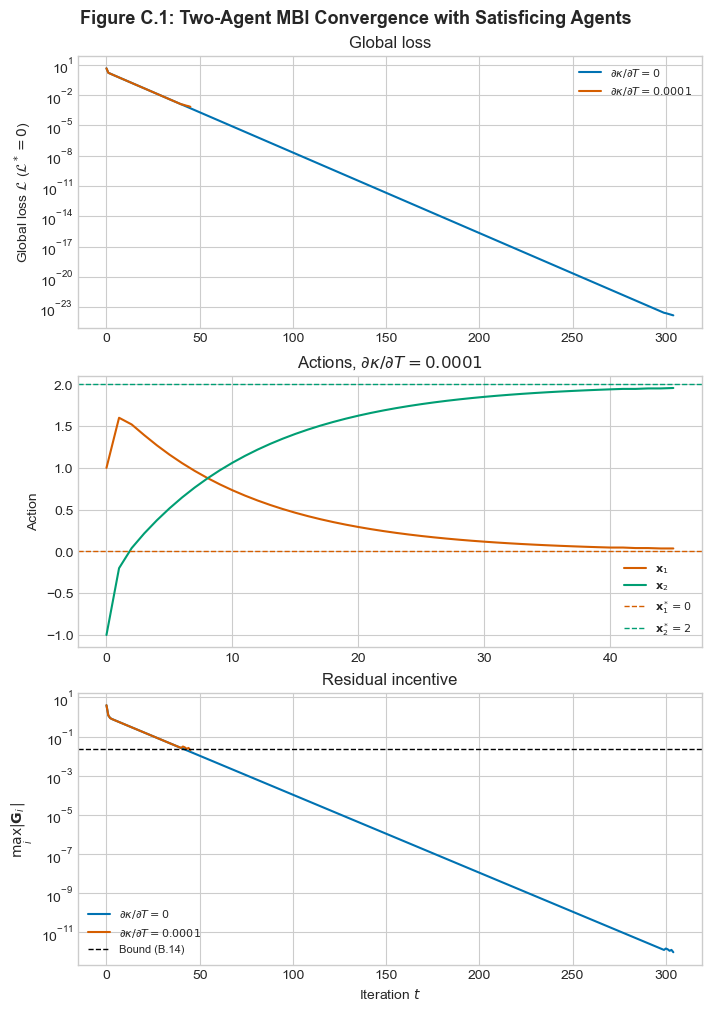

In [2]:
# ==============================================================================
# --- C.1 FOUNDATIONAL VALIDATION ---
# ==============================================================================

def c1_lipschitz_constant(lam: float) -> float:
    r"""
    Largest eigenvalue of the Hessian of $\mathcal{L} = (x_1 + x_2 - Y^*)^2 + \lambda x_1^2$,
    $H = \begin{pmatrix} 2 + 2\lambda & 2 \\ 2 & 2 \end{pmatrix}$: the Lipschitz constant $L_\nabla$
    of $\nabla \mathcal{L}$ (Theorem 4 requires $0 < \eta < 2 / L_\nabla$).
    """
    return float(np.linalg.eigvalsh(np.array([[2 + 2 * lam, 2.0], [2.0, 2.0]])).max())


def run_two_agent_mbi(Y_star: float = 2.0, lam: float = 0.5, eta: float = 0.2,
                      kappa_prime: float = 0.0, max_iters: int = 100000, tol: float = 1e-12,
                      x_init: Tuple[float, float] = (1.0, -1.0), verbose: bool = True) -> Dict[str, Any]:
    r"""
    Two-agent MBI simulation (Appendix C.1) implementing the dynamics of Theorem 4.

    Global loss: $\mathcal{L}(x_1, x_2) = (x_1 + x_2 - Y^*)^2 + \lambda x_1^2$, with $\lambda x_1^2$
    the private cost of $A_1$ and $C_2 = 0$. Each agent forms $\mathbf{G}_i = -\partial \mathcal{L} / \partial x_i$
    (Planner's price plus own marginal cost) and, simultaneously with the other agent, takes the step
    $x_i \leftarrow x_i + \eta \mathbf{G}_i$ only if $\eta \mathbf{G}_i^2 > \partial\kappa/\partial T$
    (Satisficing Check, B.13); otherwise it satisfices.

    Stopping: if kappa_prime > 0, the run stops when no agent updates (rest profile, Theorem 4 Part 2);
    if kappa_prime == 0, it stops when max_i |G_i| < tol (convergence, Theorem 4 Part 1).
    """
    L_grad = c1_lipschitz_constant(lam)
    if not (0 < eta < 2 / L_grad):
        raise ValueError(f"eta = {eta} violates 0 < eta < 2/L_grad = {2 / L_grad:.4f} (Theorem 4).")

    x1 = torch.tensor(float(x_init[0]), dtype=torch.float64, requires_grad=True)
    x2 = torch.tensor(float(x_init[1]), dtype=torch.float64, requires_grad=True)
    Y_t = torch.tensor(Y_star, dtype=torch.float64); lam_t = torch.tensor(lam, dtype=torch.float64)
    x_opt = {'x1_opt': 0.0, 'x2_opt': Y_star, 'L_opt': 0.0}
    threshold = float(np.sqrt(kappa_prime / eta))       # B.14 residual bound
    history = {'loss': [], 'x1': [], 'x2': [], 'G1': [], 'G2': [], 'G_i_max_abs': [], 'n_active': []}
    status = 'max_iters reached'

    for t in range(max_iters):
        # Planner computes the price; each agent adds its own marginal cost (autograd on L gives the sum)
        L = (x1 + x2 - Y_t) ** 2 + lam_t * x1 ** 2
        dL1, dL2 = torch.autograd.grad(L, [x1, x2])
        G = torch.stack([-dL1, -dL2]).detach()
        G_max = float(G.abs().max())
        active = (eta * G ** 2 > kappa_prime) if kappa_prime > 0 else (G.abs() >= tol)

        history['loss'].append(float(L.detach())); history['x1'].append(float(x1.detach())); history['x2'].append(float(x2.detach()))
        history['G1'].append(float(G[0])); history['G2'].append(float(G[1]))
        history['G_i_max_abs'].append(G_max); history['n_active'].append(int(active.sum()))

        if not bool(active.any()):
            status = 'rest (no agent updates)' if kappa_prime > 0 else f'converged (max|G_i| < {tol:g})'
            break
        with torch.no_grad():                            # simultaneous update of active agents
            x1 += eta * G[0] * active[0]
            x2 += eta * G[1] * active[1]

    out = {'history': history, 'x_opt': x_opt, 'iters': t, 'status': status, 'threshold': threshold,
           'L_grad': L_grad, 'eta': eta, 'kappa_prime': kappa_prime,
           'x1': history['x1'][-1], 'x2': history['x2'][-1], 'loss': history['loss'][-1],
           'G_max': history['G_i_max_abs'][-1],
           'distance': float(np.hypot(history['x1'][-1] - 0.0, history['x2'][-1] - Y_star))}
    if verbose:
        print(f"  kappa' = {kappa_prime:<8g} | {status:<32} after {t:>6} iterations | "
              f"loss = {out['loss']:.3e} | max|G_i| = {out['G_max']:.3e} "
              f"(B.14 bound {threshold:.3e}) | ||x - x*|| = {out['distance']:.3e}")
    return out


def run_robustness_check_c1(n_runs: int = 50, **kwargs) -> Dict[str, float]:
    """Repeats run_two_agent_mbi from random initial actions in [-5, 5]^2 (seeds 100 + i)."""
    dists, resid_ok = [], []
    for i in range(n_runs):
        g = torch.Generator().manual_seed(100 + i)
        x_init = tuple((torch.rand(2, generator=g, dtype=torch.float64) * 10 - 5).tolist())
        r = run_two_agent_mbi(x_init=x_init, verbose=False, **kwargs)
        dists.append(r['distance']); resid_ok.append(r['G_max'] <= r['threshold'] + 1e-12 or kwargs.get('kappa_prime', 0.0) == 0)
    print(f"  kappa' = {kwargs.get('kappa_prime', 0.0):<8g} | {n_runs} runs | mean ||x - x*|| = {np.mean(dists):.3e}"
          f" | std = {np.std(dists):.3e} | max = {np.max(dists):.3e} | all residuals within B.14: {all(resid_ok)}")
    return {'mean_distance': float(np.mean(dists)), 'std_distance': float(np.std(dists)),
            'max_distance': float(np.max(dists)), 'all_within_bound': bool(all(resid_ok))}


def plot_c1(res: Dict[float, Dict[str, Any]], kp_show: float, save_path: str):
    """Three panels: loss (log), actions vs targets, residual incentive vs the B.14 bound."""
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, ax = plt.subplots(3, 1, figsize=(7, 10), constrained_layout=True)
    h0, h = res[0.0]['history'], res[kp_show]['history']

    ax[0].plot(h0['loss'], color='#0072B2', label=r"$\partial\kappa/\partial T = 0$")
    ax[0].plot(h['loss'], color='#D55E00', label=rf"$\partial\kappa/\partial T = {kp_show:g}$")
    ax[0].set_yscale('log'); ax[0].set_ylabel(r'Global loss $\mathcal{L}$ ($\mathcal{L}^* = 0$)')
    ax[0].set_title('Global loss'); ax[0].legend(fontsize=8)

    ax[1].plot(h['x1'], color='#D55E00', label=r'$\mathbf{x}_1$')
    ax[1].plot(h['x2'], color='#009E73', label=r'$\mathbf{x}_2$')
    ax[1].axhline(res[kp_show]['x_opt']['x1_opt'], color='#D55E00', ls='--', lw=1, label=r'$\mathbf{x}_1^* = 0$')
    ax[1].axhline(res[kp_show]['x_opt']['x2_opt'], color='#009E73', ls='--', lw=1, label=r'$\mathbf{x}_2^* = 2$')
    ax[1].set_ylabel('Action'); ax[1].set_title(rf'Actions, $\partial\kappa/\partial T = {kp_show:g}$')
    ax[1].legend(fontsize=8)

    ax[2].plot(h0['G_i_max_abs'], color='#0072B2', label=r"$\partial\kappa/\partial T = 0$")
    ax[2].plot(h['G_i_max_abs'], color='#D55E00', label=rf"$\partial\kappa/\partial T = {kp_show:g}$")
    ax[2].axhline(res[kp_show]['threshold'], color='k', ls='--', lw=1, label='Bound (B.14)')
    ax[2].set_yscale('log'); ax[2].set_ylabel(r'$\max_i |\mathbf{G}_i|$')
    ax[2].set_xlabel(r'Iteration $t$'); ax[2].set_title('Residual incentive'); ax[2].legend(fontsize=8)

    fig.suptitle('Figure C.1: Two-Agent MBI Convergence with Satisficing Agents', fontsize=13, fontweight='bold')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()


# ==============================================================================
# --- EXECUTION BLOCK FOR APPENDIX C.1 ---
# ==============================================================================

if __name__ == '__main__':
    print("\n\n" + "#" * 30 + " RUNNING APPENDIX C.1 (TWO-AGENT IC/BR VALIDATION) " + "#" * 30 + "\n")
    Y_STAR, LAM, ETA = 2.0, 0.5, 0.2
    L_grad = c1_lipschitz_constant(LAM)
    print(f"L_grad = {L_grad:.6f}, 2/L_grad = {2 / L_grad:.6f}, eta = {ETA} (Theorem 4 condition satisfied)\n")

    print("Single run from x(0) = (1, -1):")
    res = {kp: run_two_agent_mbi(Y_star=Y_STAR, lam=LAM, eta=ETA, kappa_prime=kp)
           for kp in [0.0, 1e-2, 1e-4, 1e-6]}

    print("\nRobustness (random initial actions in [-5, 5]^2):")
    for kp in [0.0, 1e-4]:
        run_robustness_check_c1(n_runs=50, Y_star=Y_STAR, lam=LAM, eta=ETA, kappa_prime=kp)

    plot_c1(res, kp_show=1e-4, save_path='figure_c1_ic_br.png')

## C.2 Symmetrical Parallel System Convergence Analysis

### 1. Objective

Test the MBI's ability to drive $N$ symmetrical agents ($\lambda_i = \lambda$) toward the analytically known Global Optimum ($\mathbf{x}^*$), thereby confirming that the mechanism solves the collective action problem and maximizes global welfare, and compare the outcome with two uncoordinated benchmarks.

### 2. Methodology

The test was conducted on an N-Agent Parallel System in which the DPM coordinates decentralized agents taking simultaneous gradient steps, $\mathbf{x}_i \leftarrow \mathbf{x}_i + \eta \mathbf{G}_i$ (Theorem 4), from random initial actions in $[0, 2]$. The global loss function is defined as:

$$\mathcal{L}_{\text{global}}(\mathbf{x}) = \left(\sum_{i=1}^N \mathbf{x}_i - Y^*\right)^2 + \sum_{i=1}^N \lambda \mathbf{x}_i^2 \tag{3}$$

Two uncoordinated benchmarks quantify the value of the mechanism. In the free-rider Nash equilibrium, each agent bears its own cost and only its $1/N$ share of the system loss, minimizing $\frac{1}{N}\left(\sum_j \mathbf{x}_j - Y^*\right)^2 + \lambda \mathbf{x}_i^2$ given the other agents' actions (Nash, 1951); its symmetric solution is $\mathbf{x}^{NE} = Y^*/(N(1 + \lambda))$. In the no-transfer outcome, each agent bears only its own cost and chooses $\mathbf{x}_i = 0$.

| Parameter | Value | Description |
| :--- | :--- | :--- |
| **Number of Agents ($N$)** | $100$ | The total number of agents in the system. |
| **Global Target Output ($Y^*$)** | $10.0$ | The collective output target. |
| **Cost Penalty ($\lambda$)** | $0.1$ | Symmetrical private cost coefficient. |
| **Lipschitz bound ($L_{\nabla}$)** | $\leq 2(N + \lambda) = 200.2$ | Step-size condition $\eta < 2/L_{\nabla}$ (Theorem 4). |
| **Step size ($\eta$)** | $0.001$ | Satisfies $\eta < 2/L_{\nabla} \approx 0.00999$. |
| **Iterations** | $100,000$ | Total simulation steps. |

Table C.2.1: Symmetrical Simulation Parameters.

### 3. Key Metric

The Primary Metric for success is the Final Global Loss ($\mathcal{L}$), measured against the analytically derived optimum loss ($\mathcal{L}^*$) and the two uncoordinated benchmarks: the free-rider loss ($\mathcal{L}^{\text{NE}}$) and the no-transfer loss.

The Secondary Metrics are the Distance to the Mean Optimal Action ($|\bar{\mathbf{x}} - \mathbf{x}^*|$) and the standard deviation of the agents' actions, which confirms that every agent, and not only the average, converges.

### 4. Results

| Metric | Formula | Analytical Value | MBI (Final) |
| :--- | :--- | :--- | :--- |
| **Optimum Action ($\mathbf{x}^*$)** | $\frac{Y^*}{N+\lambda}$ | $0.099900099900$ | $0.099900099900$ (mean) |
| **Optimum Loss ($\mathcal{L}^*$)** | $\frac{\lambda Y^{*2}}{N+\lambda}$ | $0.099900099900$ | $0.099900099900$ |
| **Loss gap ($\mathcal{L} - \mathcal{L}^*$)** | | $0$ | $1.39\text{e-}17$ |
| **Std. Dev. of Actions** | | $0$ | $1.12\text{e-}09$ |
| **Free-rider NE Action ($\mathbf{x}^{NE}$)** | $\frac{Y^*}{N(1+\lambda)}$ | $0.090909090909$ | |
| **Free-rider NE Loss ($\mathcal{L}^{NE}$)** | | $0.909090909091$ | ratio to MBI: $9.1$ |
| **No-transfer Loss** | $Y^{*2}$ | $100.000000000000$ | ratio to MBI: $1001$ |

Table C.2.2: Analytical Targets and Empirical Convergence Results.

| Step size $\eta$ | Iterations to $\mathcal{L} - \mathcal{L}^* < 10^{-12}$ |
| :--- | :--- |
| $0.001$ | $71,761$ |
| $0.005$ | $14,347$ |
| $0.009$ | $7,968$ |

Table C.2.3: Iterations to convergence for admissible step sizes (same initial actions).

Figure C.2 shows the trajectory for $\eta = 0.001$; the first five iterations are omitted from the plot.

### 5. Conclusion

The empirical final loss matches the analytical optimum $\mathcal{L}^*$ to within $1.4 \times 10^{-17}$, and the standard deviation of the agents' actions falls to $1.1 \times 10^{-9}$, so every agent converges to $\mathbf{x}^*$. This validates the MBI's capacity to induce the globally optimal solution in symmetrical multi-agent settings with $N = 100$ agents.

The mean action reaches $\mathbf{x}^*$ within the first $5,000$ iterations, while the dispersion across agents decays slowly. This reflects the conditioning of the loss rather than a stability limit: the mean mode contracts quickly, the deviation modes only at the rate set by $\lambda$. Any step size below $2/L_{\nabla}$ converges, and the number of iterations is inversely proportional to the step size: $5\times$ and $9\times$ larger steps need $5.0\times$ and $9.0\times$ fewer iterations (Table C.2.3).

The achieved global loss is $9.1$ times lower than the free-rider Nash equilibrium and three orders of magnitude lower than the no-transfer outcome, confirming MBI's effectiveness in internalizing the collective externality and maximizing global welfare.



############################## RUNNING APPENDIX C.2 (SYMMETRICAL PARALLEL) ##############################

ANALYTICAL TARGETS
| Number of Agents (N)               | 100                  |
| Target Output (Y*)                 | 10.000000000000      |
| Individual Optimum (x*)            | 0.099900099900       |
| Global Loss at Optimum (L*)        | 0.099900099900       |
| Free-rider NE action (x_ne)        | 0.090909090909       |
| Free-rider NE loss (L_ne)          | 0.909090909091       |
| No-transfer action (x = 0)         | 0.000000000000       |
| No-transfer loss (Y*^2)            | 100.000000000000     |
L_grad <= 200.2000, 2/L_grad >= 0.009990, lr = 0.001
| ITER   | GLOBAL LOSS     | MEAN ACTION     | STD DEV         | MAX GRAD MAG       |
| 0      | 7469.642230891492    | 0.963563815848    | 0.544303669492    | 173.112235554714    |
| 5001   | 0.496764263781    | 0.099900099900    | 0.200178060658    | 0.076055007274    |
--------------------------------------------------

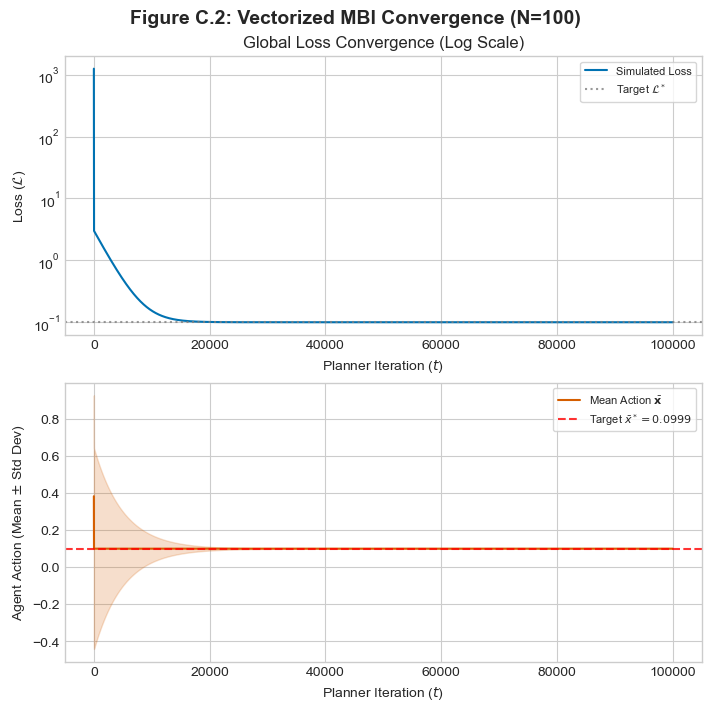

In [3]:
# ==============================================================================
# --- C.2 SYSTEM CONVERGENCE ANALYSIS - PARALLEL ---
# ==============================================================================
# Uses the universal helpers from the setup cell:
#   get_parallel_analytical_optimum, get_parallel_nash_benchmark, plot_convergence_trajectory
# (they are NOT redefined here, so the setup cell is the single source of truth).


def parallel_optimal_loss(Y_star: float, lam_t: torch.Tensor) -> float:
    r"""
    Minimum of $\mathcal{L}(\mathbf{x}) = (\sum_i \mathbf{x}_i - Y^*)^2 + \sum_i \lambda_i \mathbf{x}_i^2$:
    $\mathcal{L}^* = Y^{*2} / (1 + \sum_i 1/\lambda_i)$ (equals $\lambda Y^{*2}/(N + \lambda)$ when all $\lambda_i = \lambda$).
    """
    return float(Y_star ** 2 / (1.0 + torch.sum(1.0 / lam_t).item()))


def print_analytical_results_c2(N: int, Y_star: float, lam: float):
    """Prints the analytical optimum and both uncoordinated benchmarks for C.2."""
    x_opt_val = get_parallel_analytical_optimum(N, Y_star, lam)
    L_opt = (lam * Y_star * Y_star) / (N + lam)
    fr = get_parallel_nash_benchmark(N, Y_star, lam)        # free-rider equilibrium (setup cell)

    print("=" * 80)
    print("ANALYTICAL TARGETS")
    print("=" * 80)
    print(f"| {'Number of Agents (N)':<34} | {N:<20} |")
    print(f"| {'Target Output (Y*)':<34} | {Y_star:<20.12f} |")
    print(f"| {'Individual Optimum (x*)':<34} | {x_opt_val:<20.12f} |")
    print(f"| {'Global Loss at Optimum (L*)':<34} | {L_opt:<20.12f} |")
    print(f"| {'Free-rider NE action (x_ne)':<34} | {fr['x_ne']:<20.12f} |")
    print(f"| {'Free-rider NE loss (L_ne)':<34} | {fr['L_ne']:<20.12f} |")
    print(f"| {'No-transfer action (x = 0)':<34} | {0.0:<20.12f} |")
    print(f"| {'No-transfer loss (Y*^2)':<34} | {Y_star ** 2:<20.12f} |")
    print("=" * 80)


def print_convergence_analysis_c2(N: int, Y_star: float, lam: float, history: Dict[str, List[float]]):
    """
    Prints the final results for C.2 against the analytical optimum and two uncoordinated
    benchmarks: the free-rider Nash equilibrium (each agent bears its own cost and its 1/N share
    of the system loss) and the no-transfer outcome (each agent bears only its own cost, x_i = 0).
    """
    x_opt_val = get_parallel_analytical_optimum(N, Y_star, lam)
    L_opt = (lam * Y_star * Y_star) / (N + lam)
    fr = get_parallel_nash_benchmark(N, Y_star, lam)
    L_none = Y_star ** 2

    final_x_mean = history['x_mean'][-1]
    final_L = history['loss'][-1]
    final_std = history['x_std'][-1]

    print("\n" + "=" * 96)
    print("FINAL CONVERGENCE RESULTS (N-Agent Parallel)")
    print("=" * 96)
    print(f"| {'Metric':<28} | {'Value (MBI)':<22} | {'Target (x*)':<20} | {'Free-rider NE':<14} |")
    print("-" * 96)
    print(f"| {'Final Global Loss (L)':<28} | {final_L:<22.12f} | {L_opt:<20.12f} | {fr['L_ne']:<14.8f} |")
    print(f"| {'Final Mean Action':<28} | {final_x_mean:<22.12f} | {x_opt_val:<20.12f} | {fr['x_ne']:<14.8f} |")
    print(f"| {'Distance to Mean x*':<28} | {abs(final_x_mean - x_opt_val):<22.6e} | {'':<20} | {'':<14} |")
    print(f"| {'Final Std of Actions':<28} | {final_std:<22.6e} | {0.0:<20.12f} | {'':<14} |")
    print(f"| {'Loss gap L - L*':<28} | {final_L - L_opt:<22.6e} | {'':<20} | {'':<14} |")
    print("-" * 96)
    print(f"| {'L_ne / L (free-rider)':<28} | {fr['L_ne'] / final_L:<22.6f} | {'':<20} | {'':<14} |")
    print(f"| {'L_none / L (no transfers)':<28} | {L_none / final_L:<22.6f} | {'':<20} | {'':<14} |")
    print("=" * 96 + "\n")


def run_n_agent_parallel_mbi(N: int = 100, Y_star: float = 10.0, lam: Union[float, list, torch.Tensor] = 0.1,
                             lr: float = 0.001, num_iters: int = 100000, seed: int = 0,
                             print_freq: int = 500, is_stability_check: bool = False,
                             nonneg: bool = False, tol: float = 1e-12,
                             stop_at_tol: bool = False) -> Dict[str, Any]:
    r"""
    Runs the Vectorized N-Agent Parallel MBI simulation (Appendix C.2, C.3, C.6).

    The simulation models N agents ($\mathbf{x}_i$) and the global loss
    $\mathcal{L}(\mathbf{x}) = (\sum_{i} \mathbf{x}_i - Y^*)^2 + \sum_{i} \lambda_i \mathbf{x}_i^2$.
    All agents update simultaneously with the gradient step of Theorem 4,
    $\mathbf{x}_i \leftarrow \mathbf{x}_i + \eta \mathbf{G}_i$ with $\mathbf{G}_i = -\partial \mathcal{L} / \partial \mathbf{x}_i$
    (implemented with plain SGD on the loss, which is the same update).

    Parameters
    ----------
    N : int, optional
        The number of agents (used if `lam` is a scalar) (default is 100).
    Y_star : float, optional
        The global target output (default is 10.0).
    lam : Union[float, list, torch.Tensor], optional
        The cost penalty coefficient(s) $\lambda_i$. Scalar (symmetrical) or list/tensor
        (asymmetrical, in which case N is inferred) (default is 0.1).
    lr : float, optional
        Step size $\eta$ (default is 0.001). For standard runs it must satisfy the sufficient
        condition $\eta < 2/L_\nabla$ with $L_\nabla \leq 2(N + \max_i \lambda_i)$ (Theorem 4).
    num_iters : int, optional
        Total number of simulation steps (default is 100000).
    seed : int, optional
        Random seed for the initial actions (default is 0).
    print_freq : int, optional
        Frequency (in iterations) of the convergence trace (default is 500).
    is_stability_check : bool, optional
        If True, starts slightly off the optimum and allows step sizes that violate the
        Theorem 4 condition, to test stability and divergence (not used by the current sections) (default is False).
    nonneg : bool, optional
        If True, projects actions onto x >= 0 after each step (projected gradient descent).
        Off by default, as in Theorem 4; the optimum is interior, so the limit is unaffected.
    tol : float, optional
        Threshold for recording the first iteration at which L - L* < tol (default is 1e-12).
    stop_at_tol : bool, optional
        If True, stops the run at the first iteration with L - L* < tol (used for the
        step-size comparison in C.2); the main runs keep the default False.

    Returns
    -------
    Dict[str, Any]
        Simulation history, final state, configuration, L*, and the first iteration with L - L* < tol.
    """
    # 1. Initialization and setup
    device = torch.device('cpu')
    gen = torch.Generator(device='cpu').manual_seed(seed)
    Y_star_t = torch.tensor(Y_star, device=device, dtype=torch.float64)

    # Handle symmetrical vs. asymmetrical lambda configurations
    if isinstance(lam, (float, int)):
        lam_scalar = float(lam)
        lam_t = torch.full((N,), float(lam), device=device, dtype=torch.float64)
        is_asymmetrical = False
    elif isinstance(lam, (list, torch.Tensor)):
        lam_t = torch.as_tensor(lam, device=device, dtype=torch.float64).clone()
        lam_scalar = lam_t[0].item()       # Used only for the symmetric start in stability checks
        N = len(lam_t)
        is_asymmetrical = True
    else:
        raise TypeError("lam must be a scalar, list or PyTorch tensor.")

    # Theorem 4 step-size condition: L_grad <= 2 (N + max lambda_i) for this loss
    L_grad_bound = 2.0 * (N + float(lam_t.max()))
    if not is_stability_check and not (0 < lr < 2.0 / L_grad_bound):
        raise ValueError(f"lr = {lr} violates the sufficient condition lr < 2/L_grad = "
                         f"{2.0 / L_grad_bound:.6f} (Theorem 4).")
    if print_freq <= num_iters:
        print(f"L_grad <= {L_grad_bound:.4f}, 2/L_grad >= {2.0 / L_grad_bound:.6f}, lr = {lr}")

    L_star = parallel_optimal_loss(Y_star, lam_t)
    iters_to_tol = None

    # Initialize agent actions (x)
    if is_stability_check:
        # Stability check: start near the optimum with a small perturbation
        x_opt_val = Y_star / (N + lam_scalar)
        perturbation = 0.01
        x = torch.full((N,), x_opt_val + perturbation, device=device, dtype=torch.float64).detach()
        print(f"DEBUG START: x*={x_opt_val:.12f}, Start x_mean={x.mean().item():.12f}")
    else:
        # Standard C.2/C.3 run: start randomly in [0, 2]
        x = (torch.rand(N, generator=gen, device=device, dtype=torch.float64) * 2).detach()

    x.requires_grad_(True)
    optimizer = optim.SGD([x], lr=lr)       # x_new = x_old - lr * dL/dx = x_old + lr * G

    # History tracking
    history = {'loss': [], 'x_mean': [], 'x_std': [], 'runtime': []}
    if is_asymmetrical and N != len(lam_t.unique()):
        # Tracking for two agent types (A and B) in asymmetrical runs; assumes lam is sorted
        history['x_A_mean'] = []
        history['x_B_mean'] = []
        N_A = lam_t.tolist().count(lam_t.unique()[0].item())

    # --- INITIAL STATE (t=0) ---
    if not is_asymmetrical and print_freq <= num_iters:
        print("=" * 80)
        print(f"| {'ITER':<6} | {'GLOBAL LOSS':<15} | {'MEAN ACTION':<15} | {'STD DEV':<15} | {'MAX GRAD MAG':<18} |")
        print("=" * 80)

        optimizer.zero_grad()
        L_t0 = (x.sum() - Y_star_t) ** 2 + (lam_t * x.pow(2)).sum()
        L_t0.backward()
        G_val_t0 = x.grad.abs().max().item() if x.grad is not None else 0.0
        std_val_t0 = float(x.std().item()) if N > 1 else 0.0

        history['loss'].append(float(L_t0.item()))
        history['x_mean'].append(float(x.mean().item()))
        history['x_std'].append(std_val_t0)
        history['runtime'].append(0.0)

        print(f"| {0:<6} | {L_t0.item():.12f}{'':<3} | {x.mean().item():.12f}{'':<3} | {std_val_t0:.12f}{'':<3} | {G_val_t0:.12f}{'':<3} |")
        optimizer.zero_grad()

    # --- MAIN LOOP ---
    for t in range(num_iters):
        start_time = time.time()
        optimizer.zero_grad()

        # 2. Forward Pass: global loss L (system loss + agents' costs)
        L = (x.sum() - Y_star_t) ** 2 + (lam_t * x.pow(2)).sum()
        L_item = L.item()
        safe_max_loss = 1e300   # Cap recorded for diverged stability checks

        # 3. Divergence detection
        if not torch.isfinite(L) or L_item > 1e16:
            if is_stability_check:
                # Stability check: divergence/overflow detected
                print(f"WARNING: Numerical Overflow detected at t={t+1} (eta={lr}). Capping loss in history.")
                history['loss'].append(safe_max_loss)
                history['x_mean'].append(float('inf'))
                history['x_std'].append(float('inf'))
                remaining_steps = (num_iters + 1) - len(history['loss'])
                history['loss'].extend([safe_max_loss] * remaining_steps)
                history['x_mean'].extend([float('inf')] * remaining_steps)
                history['x_std'].extend([float('inf')] * remaining_steps)
                break
            else:
                print(f"WARNING: Divergence detected at t={t+1}. Breaking loop.")
                break

        if iters_to_tol is None and L_item - L_star < tol:
            iters_to_tol = t
            if stop_at_tol:
                history['loss'].append(L_item)
                break

        # 4. Backward Pass (DPM): G_i = -dL/dx_i
        L.backward()

        # 5. Agent Update: x_i <- x_i + lr * G_i (simultaneous)
        optimizer.step()
        if nonneg:
            with torch.no_grad():
                x.clamp_(min=0.0)

        runtime = time.time() - start_time

        # 6. Record history
        history['loss'].append(L_item)
        history['x_mean'].append(float(x.mean().item()))
        if is_asymmetrical and N != len(lam_t.unique()):
            history['x_A_mean'].append(float(x[:N_A].mean().item()))
            history['x_B_mean'].append(float(x[N_A:].mean().item()))
        std_val = float(x.std().item()) if N > 1 else 0.0
        history['x_std'].append(std_val)
        history['runtime'].append(runtime)

        # 7. Trace
        if not is_asymmetrical and print_freq <= num_iters and (t % print_freq == 0 and t != 0 or t == num_iters - 1):
            G_val = x.grad.abs().max().item() if x.grad is not None else 0.0
            print(f"| {t+1:<6} | {L_item:.12f}{'':<3} | {x.mean().item():.12f}{'':<3} | {std_val:.12f}{'':<3} | {G_val:.12f}{'':<3} |")
            if t % 5000 == 0 and t != 0 and t != num_iters - 1:
                print("-" * 80)
        elif is_asymmetrical and print_freq <= num_iters and (t % print_freq == 0 or t == num_iters - 1):
            G_val = x.grad.abs().max().item() if x.grad is not None else 0.0
            print(f"| {t:<6} | Loss: {L_item:.8f} | Mean x: {history['x_mean'][-1]:.8f} | Max Grad: {G_val:.8f} |")

    final_loss = history['loss'][-1]
    return {'history': history, 'N': N, 'Y_star': Y_star, 'lam': lam,
            'final_x_tensor': x.detach(), 'final_loss': final_loss,
            'mean_action': x.mean().item(), 'iterations': num_iters,
            'L_star': L_star, 'iters_to_tol': iters_to_tol, 'L_grad_bound': L_grad_bound}


# ==============================================================================
# --- EXECUTION BLOCK FOR APPENDIX C.2 ---
# ==============================================================================

if __name__ == '__main__':
    N_demo = 100
    Y_star_demo = 10.0
    lam_demo = 0.1
    lr_demo = 0.001
    num_iters_c2 = 100000

    print("\n\n" + "#" * 30 + " RUNNING APPENDIX C.2 (SYMMETRICAL PARALLEL) " + "#" * 30 + "\n")

    # 1. Analytical targets and benchmarks
    print_analytical_results_c2(N_demo, Y_star_demo, lam_demo)

    # 2. Main run (eta = 0.001, as in v1)
    results_c2 = run_n_agent_parallel_mbi(
        N=N_demo, Y_star=Y_star_demo, lam=lam_demo,
        lr=lr_demo, num_iters=num_iters_c2, print_freq=5000)
    history_c2 = results_c2['history']
    print_convergence_analysis_c2(N_demo, Y_star_demo, lam_demo, history_c2)

    # 3. Step size vs conditioning: iterations to reach L - L* < 1e-12 for admissible step sizes
    print("Iterations to reach L - L* < 1e-12 (same seed, same start):", flush=True)
    print(f"  lr = {lr_demo:<6}: iterations = {results_c2['iters_to_tol']} (main run)", flush=True)
    for lr_try in [0.005, 0.009]:
        r = run_n_agent_parallel_mbi(N=N_demo, Y_star=Y_star_demo, lam=lam_demo, lr=lr_try,
                                     num_iters=num_iters_c2, print_freq=num_iters_c2 + 1,
                                     stop_at_tol=True)
        print(f"  lr = {lr_try:<6}: iterations = {r['iters_to_tol']}, "
              f"final L - L* = {r['final_loss'] - r['L_star']:.3e}", flush=True)

    # 4. Figure
    x_opt_c2 = get_parallel_analytical_optimum(N_demo, Y_star_demo, lam_demo)
    L_opt_c2 = results_c2['L_star']
    plot_convergence_trajectory(
        history=history_c2,
        x_opt={'x_mean_opt': x_opt_c2, 'L_opt': L_opt_c2},
        title=f'Figure C.2: Vectorized MBI Convergence (N={N_demo})',
        save_path='figure_c2_parallel_scaling.png'
    )

## C.3 Heterogeneous Producers: A Stylized Economic Dispatch

### 1. Objective

The objective is to validate MBI in a system of fully heterogeneous agents ($\lambda_i \neq \lambda_j$) and to show what the DPM price does in that setting. The test models a stylized economic dispatch problem: several producers of the same good, with different cost structures, must jointly serve a demand target. The hypothesis is that the DPM drives each producer to its optimal output and, in doing so, equalizes the producers' marginal costs at the common price, the condition for allocating production at least total cost.

### 2. Methodology

Five generators produce a homogeneous good to serve demand $Y^* = 10$. Generator $i$ bears a private quadratic cost $\lambda_i \mathbf{x}_i^2$, and the system loss penalizes any mismatch between total output and demand. Because the good is homogeneous, the outputs are perfect substitutes and enter the loss through their sum:

$$\mathcal{L}_{\text{global}}(\mathbf{x}) = \left(\sum_{i=1}^N \mathbf{x}_i - Y^*\right)^2 + \sum_{i=1}^N \lambda_i \mathbf{x}_i^2 \tag{4}$$

The analytically optimal output of each generator is

$$\mathbf{x}_i^* = \frac{Y^*}{\lambda_i \left(1 + \sum_{j=1}^N (1/\lambda_j)\right)} \tag{5}$$

At this optimum, every generator's marginal cost $2\lambda_i \mathbf{x}_i^*$ equals the common price $2(Y^* - \sum_j \mathbf{x}_j^*)$, the marginal value of output that the DPM transmits to every producer. Generators take simultaneous gradient steps, $\mathbf{x}_i \leftarrow \mathbf{x}_i + \eta \mathbf{G}_i$ (Theorem 4), from random initial outputs in $[0, 2]$.

As in C.2, two uncoordinated benchmarks are reported. In the free-rider Nash equilibrium, each generator bears its own cost and only its $1/N$ share of the system loss, giving $\mathbf{x}_i^{NE} = Y^* / (N \lambda_i (1 + s))$ with $s = \frac{1}{N}\sum_j 1/\lambda_j$. In the no-transfer outcome, each generator bears only its own cost and produces nothing.

| Producer | Cost slope $\lambda_i$ | $\mathbf{x}_i^*$ (Optimal Output) | $\mathbf{x}_i^{NE}$ (Free-rider) |
| :--- | :--- | :--- | :--- |
| **Generator 1** | $0.1$ | $6.993006993007$ | $5.464480874317$ |
| **Generator 2** | $0.5$ | $1.398601398601$ | $1.092896174863$ |
| **Generator 3** | $1.0$ | $0.699300699301$ | $0.546448087432$ |
| **Generator 4** | $5.0$ | $0.139860139860$ | $0.109289617486$ |
| **Generator 5** | $10.0$ | $0.069930069930$ | $0.054644808743$ |

Table C.3.1: Heterogeneous Simulation Parameters ($N=5$, $Y^* = 10$). The step size $\eta = 0.01$ satisfies $\eta < 2/L_{\nabla}$, with $L_{\nabla} \leq 2(N + \max_i \lambda_i) = 30$.

### 3. Key Metric

The Primary Metric is the convergence of each generator's output $\mathbf{x}_i$ to its optimal output $\mathbf{x}_i^*$, measured by the Distance to the analytical target, together with the marginal cost of each generator against the common price, and the Final Global Loss ($\mathcal{L}$) against $\mathcal{L}^*$ and the two uncoordinated benchmarks.

### 4. Results

| Producer | $\lambda_i$ | $\mathbf{x}_i$ (MBI) | $\mathbf{x}_i^*$ (Target) | Distance | Marginal cost $2\lambda_i \mathbf{x}_i$ |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Generator 1** | $0.1$ | $6.993006993007$ | $6.993006993007$ | $7.28\text{e-}14$ | $1.398601$ |
| **Generator 2** | $0.5$ | $1.398601398601$ | $1.398601398601$ | $3.77\text{e-}14$ | $1.398601$ |
| **Generator 3** | $1.0$ | $0.699300699301$ | $0.699300699301$ | $1.58\text{e-}14$ | $1.398601$ |
| **Generator 4** | $5.0$ | $0.139860139860$ | $0.139860139860$ | $2.86\text{e-}15$ | $1.398601$ |
| **Generator 5** | $10.0$ | $0.069930069930$ | $0.069930069930$ | $1.46\text{e-}15$ | $1.398601$ |
| **Total Output ($\Sigma \mathbf{x}_i$)** | -- | $9.300699300699$ | $9.300699300699$ | $1.60\text{e-}14$ | |
| **Global Loss ($\mathcal{L}$)** | -- | $6.993006993007$ | $6.993006993007$ | $8.88\text{e-}16$ | |

Table C.3.2: Final Convergence Results for the 5-Generator Dispatch. The common price $2(Y^* - \sum_j \mathbf{x}_j)$ is $1.398601$. The loss reached $\mathcal{L} - \mathcal{L}^* < 10^{-12}$ after $2,909$ iterations.

| Outcome | Total Output | Global Loss | Ratio to MBI Loss |
| :--- | :--- | :--- | :--- |
| **MBI** | $9.300699300699$ | $6.993006993007$ | $1.000$ |
| **Free-rider Nash equilibrium** | $7.267759562842$ | $11.436591119472$ | $1.635$ |
| **No transfers** | $0$ | $100.000000000000$ | $14.3$ |

Table C.3.3: Welfare comparison with uncoordinated benchmarks.

Figure C.3 shows the mean output and the global loss; the shaded band shows the spread of outputs across generators, which converges to the spread of the heterogeneous optimum rather than to zero.

### 5. Conclusion

MBI converged the heterogeneous system to the optimal dispatch, with every generator within $10^{-13}$ of its optimal output and the final loss matching $\mathcal{L}^* \approx 6.993$ to within $10^{-15}$.

The DPM price explains the allocation. Every generator produces until its marginal cost equals the common price, so all five marginal costs coincide at $1.398601$: no reallocation of output between generators could serve the same total at lower cost. This is the equal-marginal-cost rule of economic dispatch and of competitive markets, obtained here from a single gradient signal without any generator revealing its cost. Two consequences follow. Output is inversely proportional to the cost slope, so the cheapest generator produces exactly $100$ times the output of the most expensive one. And total output ($9.30$) falls short of demand ($10$): serving the last units would cost more than the shortfall they remove, so meeting the target as a hard quota would raise the total loss.

Without coordination, free-riding generators underprovide output ($7.27$ instead of $9.30$), raising the global loss by $63.5\%$; MBI removes this inefficiency. The gain over free-riding is smaller than in the symmetrical case (C.2), because the low-cost generators already carry most of the output.



############################## RUNNING APPENDIX C.3 (HETEROGENEOUS PRODUCERS: ECONOMIC DISPATCH) ####################

ANALYTICAL TARGETS:
| Generator 1  | x*: 6.993006993007 | x_ne (free-rider): 5.464480874317
| Generator 2  | x*: 1.398601398601 | x_ne (free-rider): 1.092896174863
| Generator 3  | x*: 0.699300699301 | x_ne (free-rider): 0.546448087432
| Generator 4  | x*: 0.139860139860 | x_ne (free-rider): 0.109289617486
| Generator 5  | x*: 0.069930069930 | x_ne (free-rider): 0.054644808743
------------------------------------------------------------
| L_opt                | 6.993006993007
| Sum_x_opt            | 9.300699300699
| L_ne (free-rider)    | 11.436591119472
| L_none (no transfer) | 100.000000000000
L_grad <= 30.0000, 2/L_grad >= 0.066667, lr = 0.01
| 0      | Loss: 42.54886987 | Mean x: 1.43737572 | Max Grad: 20.61307526 |
| 5000   | Loss: 6.99300699 | Mean x: 1.86013986 | Max Grad: 0.00000000 |
| 10000  | Loss: 6.99300699 | Mean x: 1.86013986 | Max Grad: 0.00000000 |


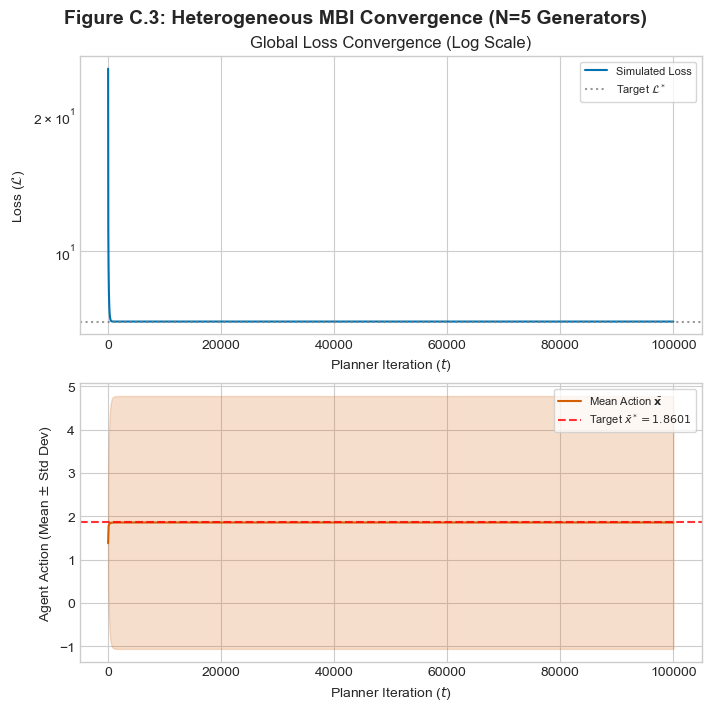

In [4]:
# ==============================================================================
# --- C.3 HETEROGENEOUS PRODUCERS: STYLIZED ECONOMIC DISPATCH ---
# ==============================================================================
# Uses the universal helpers from the setup cell:
#   get_fully_heterogeneous_targets, get_heterogeneous_nash_benchmark, plot_convergence_trajectory
# and run_n_agent_parallel_mbi / parallel_optimal_loss from the C.2 cell (not redefined here).


def print_convergence_analysis_hetero(targets: Dict[str, float], ne: Dict[str, float],
                                      LAMBDA_MAP: Dict[str, float], Y_star_set: float,
                                      results: Dict[str, Any]):
    r"""
    Prints the final results for the heterogeneous case (C.3): each producer's output against its
    analytical optimum $\mathbf{x}_i^*$, its marginal cost $2\lambda_i \mathbf{x}_i$ against the common
    price $2(Y^* - \sum_j \mathbf{x}_j)$, and the global loss against the optimum and two
    uncoordinated benchmarks (free-rider Nash equilibrium and no-transfer outcome).

    Producer i of the action tensor corresponds to the i-th key of LAMBDA_MAP (insertion order),
    because the execution block passes list(LAMBDA_MAP.values()) to the simulation.
    """
    final_L = results['history']['loss'][-1]
    final_x = results['final_x_tensor']
    agents = list(LAMBDA_MAP.keys())                 # same order as the action tensor
    L_opt, sum_x_opt = targets['L_opt'], targets['Sum_x_opt']
    L_none = Y_star_set ** 2
    sum_x = final_x.sum().item()
    price = 2.0 * (Y_star_set - sum_x)               # Planner's price: marginal value of output

    print("\n" + "=" * 124)
    print(f"FINAL CONVERGENCE RESULTS (5-Generator Dispatch, demand Y* = {Y_star_set:.6f})")
    print("=" * 124)
    print(f"| {'Producer':<12} | {'lambda_i':<8} | {'x_i (MBI)':<18} | {'x_i* (Target)':<18} | {'Distance':<10} | "
          f"{'Marginal cost':<14} | {'x_i (Free-rider NE)':<18} |")
    print("-" * 124)
    for i, agent in sorted(enumerate(agents), key=lambda p: LAMBDA_MAP[p[1]]):
        x_mbi = final_x[i].item()
        mc = 2.0 * LAMBDA_MAP[agent] * x_mbi
        print(f"| {agent:<12} | {LAMBDA_MAP[agent]:<8.1f} | {x_mbi:<18.12f} | {targets[agent]:<18.12f} | "
              f"{abs(x_mbi - targets[agent]):<10.2e} | {mc:<14.6f} | {ne[agent]:<18.12f} |")
    print("-" * 124)
    print(f"| {'TOTAL OUTPUT':<12} | {'--':<8} | {sum_x:<18.12f} | {sum_x_opt:<18.12f} | "
          f"{abs(sum_x - sum_x_opt):<10.2e} | {'':<14} | {ne['Sum_x_ne']:<18.12f} |")
    print(f"| {'GLOBAL LOSS':<12} | {'--':<8} | {final_L:<18.12f} | {L_opt:<18.12f} | "
          f"{abs(final_L - L_opt):<10.2e} | {'':<14} | {ne['L_ne']:<18.12f} |")
    print("-" * 124)
    print(f"| {'Common price 2(Y* - sum x)':<30} | {price:<12.6f} |")
    print(f"| {'L_ne / L (free-rider)':<30} | {ne['L_ne'] / final_L:<12.6f} |")
    print(f"| {'L_none / L (no transfers)':<30} | {L_none / final_L:<12.6f} |")
    lo, hi = min(agents, key=LAMBDA_MAP.get), max(agents, key=LAMBDA_MAP.get)
    print(f"| {'x_lowcost / x_highcost':<30} | {final_x[agents.index(lo)].item() / final_x[agents.index(hi)].item():<12.6f} |"
          f"  (analytical: lambda ratio {LAMBDA_MAP[hi] / LAMBDA_MAP[lo]:.1f})")
    print("=" * 124 + "\n")


# ==============================================================================
# --- EXECUTION BLOCK FOR APPENDIX C.3  ---
# ==============================================================================

if __name__ == '__main__':
    Y_star_hetero = 10.0          # demand to be served
    lr_hetero = 0.01
    num_iters_hetero = 100000

    # Five generators producing the same good, with private quadratic cost lambda_i x_i^2.
    # Lower cost slope -> larger optimal output, x_i* proportional to 1/lambda_i.
    LAMBDA_MAP = {
        'Generator 1': 0.1,
        'Generator 2': 0.5,
        'Generator 3': 1.0,
        'Generator 4': 5.0,
        'Generator 5': 10.0
    }

    print("\n\n" + "#" * 30 + " RUNNING APPENDIX C.3 (HETEROGENEOUS PRODUCERS: ECONOMIC DISPATCH) " + "#" * 20 + "\n")

    # 1. Analytical optimum and free-rider benchmark (setup-cell helpers)
    targets_hetero = get_fully_heterogeneous_targets(Y_star_hetero, LAMBDA_MAP)
    ne_hetero = get_heterogeneous_nash_benchmark(Y_star_hetero, LAMBDA_MAP)

    print("ANALYTICAL TARGETS:")
    for agent in LAMBDA_MAP:
        print(f"| {agent:<12} | x*: {targets_hetero[agent]:.12f} | x_ne (free-rider): {ne_hetero[agent]:.12f}")
    print("-" * 60)
    print(f"| {'L_opt':<20} | {targets_hetero['L_opt']:.12f}")
    print(f"| {'Sum_x_opt':<20} | {targets_hetero['Sum_x_opt']:.12f}")
    print(f"| {'L_ne (free-rider)':<20} | {ne_hetero['L_ne']:.12f}")
    print(f"| {'L_none (no transfer)':<20} | {Y_star_hetero ** 2:.12f}")
    print("=" * 60)

    # 2. Vectorized cost slopes, in LAMBDA_MAP order
    lam_hetero_vector = list(LAMBDA_MAP.values())
    N_hetero = len(lam_hetero_vector)

    # 3. Run the vectorized MBI simulation (C.2 function; checks lr < 2/L_grad)
    results_hetero = run_n_agent_parallel_mbi(
        N=N_hetero, Y_star=Y_star_hetero, lam=lam_hetero_vector,
        lr=lr_hetero, num_iters=num_iters_hetero, print_freq=5000)
    history_hetero = results_hetero['history']
    print(f"Iterations to reach L - L* < 1e-12: {results_hetero['iters_to_tol']}")

    # 4. Final analysis
    print_convergence_analysis_hetero(targets_hetero, ne_hetero, LAMBDA_MAP, Y_star_hetero, results_hetero)

    # 5. Figure: mean output; the band shows the spread across producers, which converges to the
    #    spread of the heterogeneous optimum, not to zero.
    x_mean_target_hetero = targets_hetero['Sum_x_opt'] / N_hetero
    plot_convergence_trajectory(
        history=history_hetero,
        x_opt={'x_mean_opt': x_mean_target_hetero, 'L_opt': targets_hetero['L_opt']},
        title=f'Figure C.3: Heterogeneous MBI Convergence (N={N_hetero} Generators)',
        save_path='figure_c3_heterogeneous_dispatch.png'
    )

## C.4 Model-Based MBI vs. Model-Free Reinforcement Learning Benchmark

### 1. Objective

The objective of this analysis is to contextualize the MBI framework by comparing its sample efficiency with a widely used Model-Free Reinforcement Learning (RL) method, Proximal Policy Optimization (PPO) (Schulman et al., 2017), on the same coordination task. The two approaches address different settings: MBI uses the gradient of a known, differentiable global loss, while PPO treats the loss as a black-box reward. The comparison therefore quantifies the value of exploiting the known loss structure when it is available, rather than ranking two methods for the same setting.

### 2. Methodology

Three agents choose vector-valued actions $\mathbf{x}_i \in \mathbb{R}^4$ to bring their mean action to a target $\mathbf{y}^* = (1, -1, 2, -0.5)$, with a penalty on disagreement between agents:

$$\mathcal{L}_{\text{global}}(\mathbf{X}) = \left\| \bar{\mathbf{x}} - \mathbf{y}^* \right\|^2 + \tfrac{1}{2} \, \mathrm{mean}_d \, \mathrm{Var}_i(x_{i,d}), \qquad \bar{\mathbf{x}} = \tfrac{1}{N}\sum_i \mathbf{x}_i \tag{6}$$

The minimum is $\mathcal{L}^* = 0$, reached when every agent plays $\mathbf{y}^*$.

* **MBI:** all agents start at $\mathbf{x}_i = \mathbf{0}$ and take simultaneous gradient steps $\mathbf{x}_i \leftarrow \mathbf{x}_i + \eta \mathbf{G}_i$ (Theorem 4) with $\eta = 0.05$, which satisfies $\eta < 2/L_{\nabla} = 3$ ($L_{\nabla} = 2/3$, computed from the Hessian). Each step uses one gradient evaluation of the known loss, which returns all $N \cdot 4$ partial derivatives.
* **PPO:** each agent has its own actor-critic policy (one hidden layer of 32 units) and receives the shared team reward $-\mathcal{L}_{\text{global}}$. Each step draws 16 joint rollouts, followed by 4 epochs of clipped-surrogate updates (clip $0.2$, Adam, learning rate $0.01$, entropy bonus $0.01$). The context is constant, so the task is a single-state (bandit) problem. The hyperparameters are fixed and were not tuned. Performance is measured at the policy mean, over 10 seeds.

Both methods run for 120 steps: MBI uses 120 gradient evaluations, PPO $120 \times 16 = 1,920$ loss evaluations.

| Feature | MBI | Model-Free PPO |
| :--- | :--- | :--- |
| **Information** | Gradient of the known $\mathcal{L}_{\text{global}}$ | Scalar reward $-\mathcal{L}_{\text{global}}$ from sampled actions |
| **Oracle call** | Gradient evaluation (all partial derivatives) | Loss evaluation (one scalar) |
| **Optimization** | Deterministic gradient steps | Stochastic policy-gradient updates |
| **Convergence guarantee** | Yes, under Theorem 4 (convex loss, $\eta < 2/L_{\nabla}$) | No general guarantee; depends on exploration and hyperparameters |

Table C.4.1: Comparison of MBI and Model-Free PPO.

### 3. Key Metric

The primary metric is the global loss at the policy (MBI action or PPO policy mean) as a function of the cumulative number of oracle calls. Secondary metrics are the number of MBI gradient evaluations needed to reach PPO's final loss, and PPO's loss at a budget comparable to MBI's.

### 4. Results

| Method | Oracle calls | Final loss |
| :--- | :--- | :--- |
| **MBI** | $120$ gradient evaluations | $0.001958$ |
| **PPO (10 seeds)** | $1,920$ loss evaluations | $0.019989 \pm 0.007236$ (mean $\pm$ s.d.) |
| PPO, median [IQR] | | $0.020659$ $[0.015729, 0.023369]$ |
| PPO, min / max | | $0.007934$ / $0.033286$ |
| Initial loss ($\mathbf{x} = \mathbf{0}$) | | $6.250000$ |

Table C.4.2: Final loss after 120 steps.

| Comparison | Value |
| :--- | :--- |
| **MBI gradient evaluations to reach PPO's mean final loss** | $86$ (PPO: $1,920$ loss evaluations) |
| **PPO mean loss after 128 loss evaluations** (comparable to MBI's 120) | $0.224667$ (MBI after 120: $0.001958$) |

Table C.4.3: Sample-efficiency comparison.

Figure C.4 shows the loss against cumulative oracle calls; the shaded band is the PPO interquartile range across seeds.

### 5. Conclusion

When the global loss is known and differentiable, gradient-based incentives are far more sample-efficient than model-free learning. After 120 steps, MBI reaches a loss about ten times lower than the PPO mean, using 120 gradient evaluations against PPO's 1,920 loss evaluations; MBI reaches PPO's final loss after 86 gradient evaluations. At a comparable budget of about 120 oracle calls, PPO's loss is still more than a hundred times higher than MBI's. The MBI loss has not reached its minimum at step 120: it decreases geometrically toward $\mathcal{L}^* = 0$, as Theorem 4 predicts, while PPO's improvement depends on stochastic exploration and varies across seeds.

The comparison should be read with its scope in mind. A gradient evaluation returns more information than a single loss evaluation, and the advantage shown here is precisely the value of that information when the loss is available. PPO is designed for settings where it is not: unknown dynamics, non-differentiable rewards or sequential decisions, none of which this single-state task exercises, and its hyperparameters were not tuned. PPO is therefore a reference point for a different paradigm rather than a rival on its own ground.



############################## RUNNING APPENDIX C.4 (MBI vs PPO SAMPLE EFFICIENCY) ##############################

N = 3 agents, actions in R^4, L* = 0
L_grad = 0.666667, 2/L_grad = 3.000000, MBI lr = 0.05 (Theorem 4 condition satisfied)

| Method                             | Oracle calls           | Final loss (mean ± std)    |
--------------------------------------------------------------------------------------------
| MBI (gradient of known loss)       | 120 gradient evals     | 0.001958                   |
| PPO, 10 seeds (black-box reward)   | 1920 loss evals        | 0.019989 ± 0.007236        |
--------------------------------------------------------------------------------------------
| PPO final loss: median [IQR]       |                        | 0.020659 [0.015729, 0.023369] |
| PPO final loss: min / max          |                        | 0.007934 / 0.033286        |
| Initial loss (x = 0)               |                        | 6.250000                   |
------------

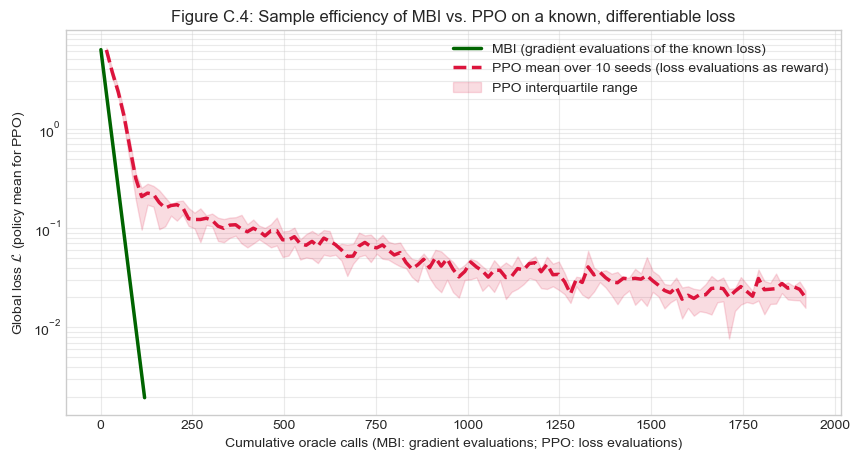

In [5]:
# ==============================================================================
# --- C.4 MBI vs. MODEL-FREE RL (PPO): SAMPLE-EFFICIENCY BENCHMARK ---
# ==============================================================================
# Uses set_global_seed from the setup cell. torch, optim, np, plt are imported there.
import torch.nn as nn

# --- SYSTEM PARAMETERS ---
C4_NUM_AGENTS = 3
C4_ACTION_DIM = 4                                   # vector-valued actions, x_i in R^4
C4_STATE_DIM = C4_ACTION_DIM
C4_TARGET = torch.tensor([1.0, -1.0, 2.0, -0.5], dtype=torch.float32)


def c4_global_loss(actions: torch.Tensor) -> torch.Tensor:
    r"""
    Global loss for C.4 (actions: N x D):
    $\mathcal{L} = \|\bar{\mathbf{x}} - \mathbf{y}^*\|^2 + \tfrac{1}{2}\,\mathrm{mean}_d \mathrm{Var}_i(x_{i,d})$,
    with $\bar{\mathbf{x}}$ the mean action across agents (consensus on a target plus an alignment term).
    The minimum is $\mathcal{L}^* = 0$, reached when every agent plays $\mathbf{y}^*$.
    """
    collective_action = torch.mean(actions, dim=0)
    task_loss = torch.sum((collective_action - C4_TARGET) ** 2)
    variance_penalty = torch.mean(torch.var(actions, dim=0)) if C4_NUM_AGENTS > 1 else 0.0
    return task_loss + 0.5 * variance_penalty


def c4_lipschitz_constant() -> float:
    """Largest eigenvalue of the (constant) Hessian of c4_global_loss: L_grad of Theorem 4."""
    flat = torch.zeros(C4_NUM_AGENTS * C4_ACTION_DIM, dtype=torch.float64)
    H = torch.autograd.functional.hessian(
        lambda v: c4_global_loss(v.view(C4_NUM_AGENTS, C4_ACTION_DIM).float()).double(), flat)
    return float(torch.linalg.eigvalsh(H).max())


# ==========================================
# 1. MBI (gradient incentives from the known loss)
# ==========================================
class MBIAgent:
    def __init__(self, lr: float):
        self.x = torch.zeros(C4_ACTION_DIM, requires_grad=True)
        self.optimizer = optim.SGD([self.x], lr=lr)

    def step(self, incentive: torch.Tensor) -> torch.Tensor:
        # SGD minimizes; setting grad = -G_i gives x <- x + lr * G_i
        self.optimizer.zero_grad()
        self.x.grad = -incentive
        self.optimizer.step()
        return self.x.detach().clone()


# ==========================================
# 2. PROXIMAL POLICY OPTIMIZATION (PPO), one policy per agent, shared team reward
# ==========================================
class PPOAgent(nn.Module):
    def __init__(self):
        super().__init__()
        self.actor = nn.Sequential(nn.Linear(C4_STATE_DIM, 32), nn.Tanh(), nn.Linear(32, C4_ACTION_DIM))
        self.critic = nn.Sequential(nn.Linear(C4_STATE_DIM, 32), nn.Tanh(), nn.Linear(32, 1))
        self.log_std = nn.Parameter(torch.zeros(C4_ACTION_DIM) - 0.5)

    def get_action(self, state, deterministic=False):
        mu = self.actor(state)
        if deterministic:
            return mu, None
        dist = torch.distributions.Normal(mu, torch.exp(self.log_std))
        action = dist.sample()
        return action, dist.log_prob(action).sum(dim=-1)

    def evaluate(self, state, action):
        mu = self.actor(state)
        dist = torch.distributions.Normal(mu, torch.exp(self.log_std))
        return dist.log_prob(action).sum(dim=-1), self.critic(state), dist.entropy().sum(dim=-1)


def run_mbi_c4(max_steps: int, lr: float) -> List[float]:
    """MBI: one gradient evaluation of the known loss per step; all agents update simultaneously."""
    agents = [MBIAgent(lr) for _ in range(C4_NUM_AGENTS)]
    history = []
    for _ in range(max_steps):
        for a in agents:
            a.x.grad = None                          # clear: backward() accumulates gradients
        actions = torch.stack([a.x for a in agents])
        loss = c4_global_loss(actions)
        history.append(loss.item())                 # loss before the step (evaluation count = step)
        loss.backward()                              # DPM: G_i = -dL/dx_i for every agent at once
        incentives = [-a.x.grad.clone() for a in agents]
        for a, g in zip(agents, incentives):
            a.step(g)
    return history


def run_ppo_c4(seed: int, max_steps: int, batch_size: int, epochs: int, clip_eps: float,
               lr: float, shared_state: torch.Tensor) -> List[float]:
    """PPO on the same loss as a black box: each step draws batch_size joint rollouts (team reward -L)."""
    set_global_seed(seed)
    agents = [PPOAgent() for _ in range(C4_NUM_AGENTS)]
    opts = [optim.Adam(a.parameters(), lr=lr) for a in agents]
    history = []
    for _ in range(max_steps):
        # Evaluate the policy mean (exploration noise removed)
        with torch.no_grad():
            mean_actions = torch.stack([a.get_action(shared_state, deterministic=True)[0] for a in agents])
            history.append(c4_global_loss(mean_actions).item())

        # Collect a batch of joint rollouts
        states_buf, actions_buf, logp_buf, rewards_buf = [], [], [], []
        with torch.no_grad():
            for _ in range(batch_size):
                acts, lps = zip(*[a.get_action(shared_state) for a in agents])
                acts_t = torch.stack(acts)
                states_buf.append(shared_state); actions_buf.append(acts_t)
                logp_buf.append(torch.stack(lps)); rewards_buf.append(-c4_global_loss(acts_t).item())
        states_t = torch.stack(states_buf); actions_t = torch.stack(actions_buf)
        old_logp_t = torch.stack(logp_buf)
        rewards_t = torch.tensor(rewards_buf, dtype=torch.float32).unsqueeze(-1)

        # Clipped-surrogate updates, one policy per agent
        for _ in range(epochs):
            for i, (agent, opt) in enumerate(zip(agents, opts)):
                opt.zero_grad()
                new_logp, values, entropy = agent.evaluate(states_t, actions_t[:, i, :])
                ratios = torch.exp(new_logp - old_logp_t[:, i].detach())
                adv = (rewards_t - values.detach()).squeeze(-1)
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
                actor_loss = -torch.min(ratios * adv,
                                        torch.clamp(ratios, 1 - clip_eps, 1 + clip_eps) * adv).mean()
                critic_loss = nn.MSELoss()(values, rewards_t)
                (actor_loss + 0.5 * critic_loss - 0.01 * entropy.mean()).backward()
                opt.step()
    return history


# ==============================================================================
# --- EXECUTION BLOCK FOR APPENDIX C.4 ---
# ==============================================================================

if __name__ == '__main__':
    MAX_STEPS = 120
    MBI_LR = 0.05
    PPO_EPOCHS, PPO_BATCH, PPO_CLIP, PPO_LR = 4, 16, 0.2, 0.01
    NUM_SEEDS = 10
    shared_state = torch.ones(C4_STATE_DIM)          # constant context: a single-state (bandit) task

    print("\n\n" + "#" * 30 + " RUNNING APPENDIX C.4 (MBI vs PPO SAMPLE EFFICIENCY) " + "#" * 30 + "\n")

    L_grad = c4_lipschitz_constant()
    print(f"N = {C4_NUM_AGENTS} agents, actions in R^{C4_ACTION_DIM}, L* = 0")
    print(f"L_grad = {L_grad:.6f}, 2/L_grad = {2 / L_grad:.6f}, MBI lr = {MBI_LR} "
          f"(Theorem 4 condition {'satisfied' if MBI_LR < 2 / L_grad else 'VIOLATED'})\n")

    # --- MBI (deterministic: agents start at x_i = 0) ---
    mbi_history = run_mbi_c4(MAX_STEPS, MBI_LR)
    mbi_evals = np.arange(1, MAX_STEPS + 1)               # one gradient evaluation per step

    # --- PPO over seeds ---
    ppo_histories = np.array([run_ppo_c4(s, MAX_STEPS, PPO_BATCH, PPO_EPOCHS, PPO_CLIP, PPO_LR, shared_state)
                              for s in range(NUM_SEEDS)])
    ppo_evals = PPO_BATCH * np.arange(1, MAX_STEPS + 1)   # batch_size loss evaluations per step

    # --- Summary ---
    ppo_final = ppo_histories[:, -1]
    ppo_mean_curve = ppo_histories.mean(axis=0)
    reach = np.where(np.array(mbi_history) <= ppo_final.mean())[0]
    mbi_evals_to_match = int(mbi_evals[reach[0]]) if reach.size else None
    k_equal = int(np.ceil(MAX_STEPS / PPO_BATCH))   # PPO steps using about MAX_STEPS rollouts

    print("=" * 92)
    print(f"| {'Method':<34} | {'Oracle calls':<22} | {'Final loss (mean ± std)':<26} |")
    print("-" * 92)
    print(f"| {'MBI (gradient of known loss)':<34} | {f'{MAX_STEPS} gradient evals':<22} | {mbi_history[-1]:<26.6f} |")
    print(f"| {'PPO, 10 seeds (black-box reward)':<34} | {f'{int(ppo_evals[-1])} loss evals':<22} | "
          f"{f'{ppo_final.mean():.6f} ± {ppo_final.std(ddof=1):.6f}':<26} |")
    print("-" * 92)
    print(f"| {'PPO final loss: median [IQR]':<34} | {'':<22} | "
          f"{f'{np.median(ppo_final):.6f} [{np.percentile(ppo_final, 25):.6f}, {np.percentile(ppo_final, 75):.6f}]':<26} |")
    print(f"| {'PPO final loss: min / max':<34} | {'':<22} | {f'{ppo_final.min():.6f} / {ppo_final.max():.6f}':<26} |")
    print(f"| {'Initial loss (x = 0)':<34} | {'':<22} | {mbi_history[0]:<26.6f} |")
    print("-" * 92)
    print(f"MBI gradient evaluations to reach PPO's mean final loss: {mbi_evals_to_match}")
    print(f"PPO mean loss after {k_equal} steps ({k_equal * PPO_BATCH} loss evals, comparable to MBI's {MAX_STEPS}): "
          f"{ppo_mean_curve[k_equal - 1]:.6f}")
    print("=" * 92 + "\n")

    # --- Figure ---
    lo, hi = np.percentile(ppo_histories, [25, 75], axis=0)
    plt.figure(figsize=(10, 5))
    plt.plot(mbi_evals, mbi_history, label='MBI (gradient evaluations of the known loss)',
             linewidth=2.5, color='darkgreen')
    plt.plot(ppo_evals, ppo_mean_curve, label='PPO mean over 10 seeds (loss evaluations as reward)',
             linewidth=2.5, color='crimson', linestyle='--')
    plt.fill_between(ppo_evals, lo, hi, color='crimson', alpha=0.15, label='PPO interquartile range')
    plt.yscale('log')
    plt.xlabel('Cumulative oracle calls (MBI: gradient evaluations; PPO: loss evaluations)')
    plt.ylabel(r'Global loss $\mathcal{L}$ (policy mean for PPO)')
    plt.title('Figure C.4: Sample efficiency of MBI vs. PPO on a known, differentiable loss')
    plt.legend(); plt.grid(True, which='both', ls='-', alpha=0.4)
    plt.savefig('figure_c4_mbi_vs_ppo.png', dpi=300, bbox_inches='tight')
    plt.show()

## C.5 Algorithmic Stability and Convergence Dynamics

### 1. Objective

The objective of this analysis is to validate empirically the step-size condition of Theorem 4: simultaneous gradient steps converge when the step size satisfies $\eta < \eta_{\max} = 2/L_{\nabla}$, and exceeding this bound leads to exponential divergence.

### 2. Methodology

MBI is applied to the Symmetrical Parallel System ($N=100$, $Y^* = 10$, $\lambda=0.01$), whose optimum loss is analytically known, $\mathcal{L}^* = \lambda Y^{*2}/(N+\lambda) = 0.009999000100$. The Hessian of the loss is $2(\mathbf{1}\mathbf{1}^\top + \lambda I)$, with largest eigenvalue $L_{\nabla} = 2(N + \lambda) = 200.02$, so $\eta_{\max} = 1/(N + \lambda) \approx 0.009999$. Along each eigendirection, the error is multiplied at every step by $1 - \eta \mu$, where $\mu$ is the eigenvalue; the run converges if $|1 - \eta L_{\nabla}| < 1$ and diverges otherwise.

All agents start at $\mathbf{x}_i = 1$, so only the mean mode (eigenvalue $L_{\nabla}$) is excited. This is the mode that determines the stability boundary; the dispersion modes, with eigenvalue $2\lambda$, converge more slowly, as shown in C.2. The simulation runs for $T = 1000$ steps and stops as soon as the loss becomes non-finite or exceeds $10^{16}$, recording that iteration. Five step sizes are tested: two well inside the envelope, one just inside ($0.99\,\eta_{\max}$), one just outside ($1.01\,\eta_{\max}$) and one far outside ($\eta = 1.1$).

### 3. Key Metric

The primary metrics are the outcome of each run (convergence or divergence, and the iteration of divergence) against the outcome predicted by the contraction factor $|1 - \eta L_{\nabla}|$, and the final loss gap $\mathcal{L} - \mathcal{L}^*$ for the converging runs.

### 4. Results

| Step size | $\eta$ | $\lvert 1 - \eta L_{\nabla} \rvert$ | Predicted | Outcome | $\mathcal{L} - \mathcal{L}^*$ (last finite) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Small | $0.0005$ | $0.89999$ | converge | finite after $1000$ steps | $-3.5\text{e-}18$ |
| Moderate | $0.005$ | $0.0001$ | converge | finite after $1000$ steps | $-6.9\text{e-}18$ |
| $0.99\,\eta_{\max}$ | $0.009899010$ | $0.98$ | converge | finite after $1000$ steps | $2.4\text{e-}14$ |
| $1.01\,\eta_{\max}$ | $0.010098990$ | $1.02$ | diverge | diverged at $t = 703$ | $9.6\text{e+}15$ |
| Far above | $1.1$ | $219.02$ | diverge | diverged at $t = 3$ | $1.9\text{e+}13$ |

Table C.5.1: Stability of MBI gradient steps across step sizes ($\eta_{\max} \approx 0.009999$). Negative gaps are floating-point rounding at $\mathcal{L}^*$.

Figure C.5 shows the loss gap over time; the stable runs flatten at the floating-point floor, and the unstable runs end at the iteration where they diverge.

### 5. Conclusion

The results match the step-size condition of Theorem 4 in every case. All step sizes below $\eta_{\max}$ converge to $\mathcal{L}^*$ to machine precision, and both step sizes above it diverge. The boundary is sharp: a step $1\%$ below $\eta_{\max}$ converges, while a step $1\%$ above diverges, after $703$ iterations because the error grows by only a factor of $1.02$ per step; far above the bound, divergence occurs within $3$ iterations. The speed of the stable runs is set by the contraction factor of the mean mode, which is close to zero for $\eta = 0.005$; with heterogeneous initial actions, the dispersion modes would converge at the slower rate set by $\lambda$ (C.2).

Because the loss is known, its curvature, and therefore $\eta_{\max}$, can be computed before running the mechanism, so a stable step size can be chosen without trial and error.



############################## RUNNING APPENDIX C.5 (ALGORITHMIC STABILITY) ##############################

N = 100, lambda = 0.01, Y* = 10.0, x_i(0) = 1.0
L_grad = 2(N + lambda) = 200.0200, eta_max = 2/L_grad = 0.009999000, L* = 0.009999000100

| Step size                      | eta          | |1 - eta L_grad| | Predicted  | Outcome                    | L - L* (last finite) |
----------------------------------------------------------------------------------------------------------------
| eta = 0.0005 (small)           | 0.000500000  | 0.899990         | converge   | finite after 1000 steps    | -3.469447e-18        |
| eta = 0.005 (moderate)         | 0.005000000  | 0.000100         | converge   | finite after 1000 steps    | -6.938894e-18        |
| eta = 0.99 eta_max             | 0.009899010  | 0.980000         | converge   | finite after 1000 steps    | 2.389755e-14         |
| eta = 1.01 eta_max             | 0.010098990  | 1.020000         | diverge    | diverged at t = 703  

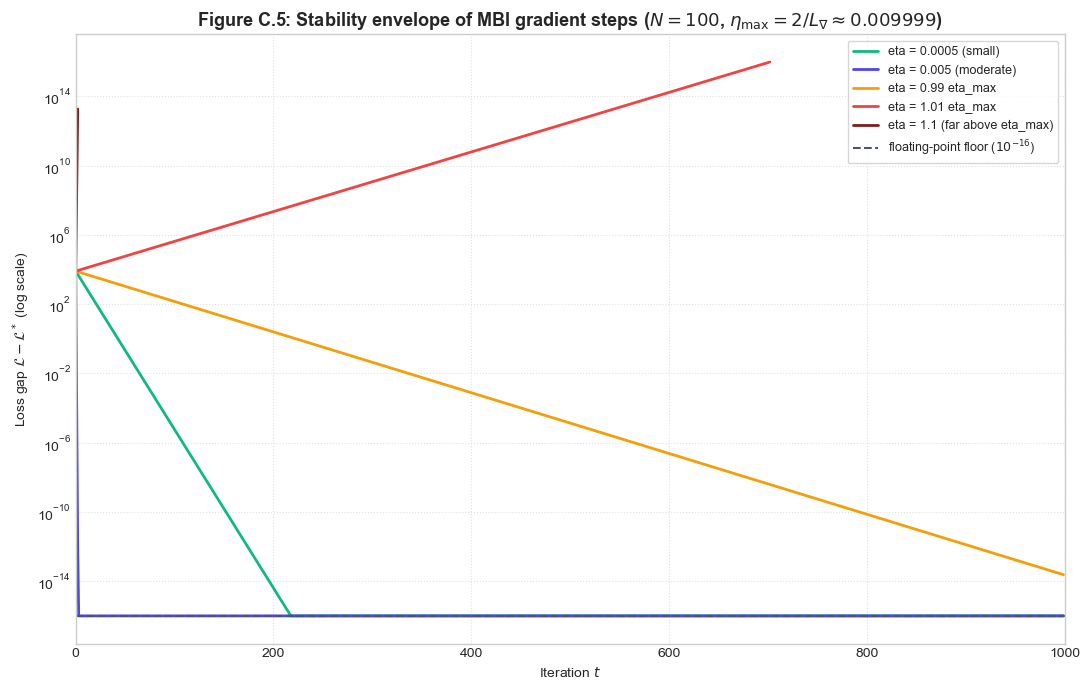

In [6]:
# ==============================================================================
# --- C.5 ALGORITHMIC STABILITY ---
# ==============================================================================

def global_loss_c5(x: np.ndarray, Y_star: float, lam: float) -> float:
    """Global loss of the N-agent parallel system: (sum x - Y*)^2 + lam * sum x^2."""
    return float((np.sum(x) - Y_star) ** 2 + lam * np.sum(x ** 2))


def analytical_gradient_c5(x: np.ndarray, Y_star: float, lam: float) -> np.ndarray:
    """dL/dx_i = 2 (sum x - Y*) + 2 lam x_i."""
    return 2.0 * (np.sum(x) - Y_star) + 2.0 * lam * x


def simulate_gd_c5(N: int, Y_star: float, lam: float, eta: float, num_iters: int,
                   x0: float = 1.0, blowup: float = 1e16) -> Dict[str, Any]:
    r"""
    Simultaneous gradient steps x <- x + eta * G with G = -dL/dx (Theorem 4), from x_i = x0 for all i.
    Stops and records the iteration when the loss exceeds `blowup` or becomes non-finite.
    No values are imposed: the recorded history is exactly what the iteration produces.
    """
    x = np.full(N, float(x0))
    history, diverged_at = [], None
    with np.errstate(over='ignore', invalid='ignore'):
        for t in range(num_iters):
            L = global_loss_c5(x, Y_star, lam)
            if not np.isfinite(L) or L > blowup:
                diverged_at = t
                break
            history.append(L)
            x = x - eta * analytical_gradient_c5(x, Y_star, lam)
    return {'history': history, 'diverged_at': diverged_at, 'final_x': x}


def plot_stability_c5(runs: Dict[str, Dict[str, Any]], L_star: float, zoom: int, eta_max: float):
    """Log-scale plot of the loss gap L - L* for each step size (diverged runs end where they blow up)."""
    FLOOR = 1e-16                     # floating-point floor: gaps below this are rounding noise
    plt.style.use('seaborn-v0_8-whitegrid')
    plt.figure(figsize=(11, 7))
    colors = ['#10B981', '#4F46E5', '#F59E0B', '#EF4444', '#7F1D1D']
    for (name, r), c in zip(runs.items(), colors):
        gap = np.array(r['history'][:zoom]) - L_star
        plt.plot(np.arange(len(gap)), np.maximum(np.abs(gap), FLOOR), label=name, color=c, linewidth=2)
    plt.yscale('log')
    plt.axhline(FLOOR, color='#4B5563', linestyle='--', linewidth=1.5,
                label=r'floating-point floor ($10^{-16}$)')
    plt.xlim(0, zoom)
    plt.title(rf'Figure C.5: Stability envelope of MBI gradient steps ($N=100$, $\eta_{{\max}} = 2/L_\nabla \approx {eta_max:.6f}$)',
              fontsize=13, fontweight='bold')
    plt.xlabel(r'Iteration $t$')
    plt.ylabel(r'Loss gap $\mathcal{L} - \mathcal{L}^*$ (log scale)')
    plt.legend(fontsize=9, loc='upper right', frameon=True)
    plt.grid(True, which='both', ls=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig('figure_c5_stability.png', dpi=300, bbox_inches='tight')
    plt.show()


# ==============================================================================
# --- EXECUTION BLOCK FOR APPENDIX C.5 ---
# ==============================================================================

if __name__ == '__main__':
    N_C5, Y_STAR_C5, LAM_C5 = 100, 10.0, 0.01
    NUM_ITERS_C5 = 1000
    X0_C5 = 1.0                       # identical start for all agents: only the mean mode is excited

    # Hessian of L: 2 (1 1^T + lam I); eigenvalues 2 (N + lam) (mean mode) and 2 lam (dispersion modes)
    L_grad = 2.0 * (N_C5 + LAM_C5)
    eta_max = 2.0 / L_grad            # = 1 / (N + lam)
    L_star = LAM_C5 * Y_STAR_C5 ** 2 / (N_C5 + LAM_C5)

    step_sizes = {
        'eta = 0.0005 (small)':          0.0005,
        'eta = 0.005 (moderate)':        0.005,
        'eta = 0.99 eta_max':            0.99 * eta_max,
        'eta = 1.01 eta_max':            1.01 * eta_max,
        'eta = 1.1 (far above eta_max)': 1.1,
    }

    print("\n\n" + "#" * 30 + " RUNNING APPENDIX C.5 (ALGORITHMIC STABILITY) " + "#" * 30 + "\n")
    print(f"N = {N_C5}, lambda = {LAM_C5}, Y* = {Y_STAR_C5}, x_i(0) = {X0_C5}")
    print(f"L_grad = 2(N + lambda) = {L_grad:.4f}, eta_max = 2/L_grad = {eta_max:.9f}, L* = {L_star:.12f}\n")

    runs = {name: simulate_gd_c5(N_C5, Y_STAR_C5, LAM_C5, eta, NUM_ITERS_C5, X0_C5)
            for name, eta in step_sizes.items()}

    print("=" * 112)
    print(f"| {'Step size':<30} | {'eta':<12} | {'|1 - eta L_grad|':<16} | {'Predicted':<10} | {'Outcome':<26} | {'L - L* (last finite)':<20} |")
    print("-" * 112)
    for (name, eta), r in zip(step_sizes.items(), runs.values()):
        rho = abs(1.0 - eta * L_grad)
        predicted = 'converge' if eta < eta_max else 'diverge'
        outcome = (f"diverged at t = {r['diverged_at']}" if r['diverged_at'] is not None
                   else f"finite after {NUM_ITERS_C5} steps")
        last_gap = r['history'][-1] - L_star
        print(f"| {name:<30} | {eta:<12.9f} | {rho:<16.6f} | {predicted:<10} | {outcome:<26} | {last_gap:<20.6e} |")
    print("=" * 112 + "\n")

    plot_stability_c5(runs, L_star, zoom=NUM_ITERS_C5, eta_max=eta_max)

## C.6 Private Costs and Asymmetric Information

### 1. Objective

The objective is to validate Theorem 3 (Appendix B.5) on the role of private costs. Under the mechanism of Appendix B.1.1, agents add their own true marginal cost and the Planner never uses its belief about costs, so asymmetric information causes no welfare loss (Part 1). In the alternative setting in which the Planner prices an agent's cost itself with an estimate $\hat{\lambda}$, the test measures the welfare loss caused by misestimation and verifies that pricing with the expected cost minimizes the expected loss (Part 2).

### 2. Methodology

In the Part 2 setting, agents take simultaneous gradient steps (Theorem 4) on the loss priced with $\hat{\lambda}$, and the resulting actions are evaluated with the true costs. Every simulated outcome is checked against its closed form, obtained by substituting the optimum of the priced loss into the true loss. Three experiments are reported:

* **A. Misspecification of all agents' costs.** Symmetrical Parallel System ($N=100$, $Y^*=10$, true $\lambda=0.1$), priced with $\hat{\lambda} = f\lambda$ for $f \in \{0.5, 0.9, 1.1, 1.5, 2.0\}$, step size $\eta = 0.009$:

$$\hat{\mathcal{L}}(\mathbf{x}) = \left(\sum_{i=1}^N \mathbf{x}_i - Y^*\right)^2 + \hat{\lambda} \sum_{i=1}^N \mathbf{x}_i^2 \tag{7}$$

* **B. One agent's cost misestimated.** Heterogeneous team of five agents ($Y^* = 7.461$, true $\lambda = (0.3, 0.5, 0.2, 0.4, 0.6)$, $\eta = 0.1$), in which the Planner prices agent 1's cost with its true value $0.3$, a guess $0.1$, or the expected value $0.2$.
* **C. Certainty equivalence.** For the team of B, agent 1's cost is either $0.1$ or $0.3$ with equal probability ($E[\lambda_1] = 0.2$). The penalty of each pricing choice is computed in closed form for both types and averaged under this prior; the minimizer of the expected penalty is located on a grid, and the exercise is repeated for two further priors.

The penalty is the true loss of the outcome minus the optimum under the true costs.

### 3. Key Metric

The primary metrics are the relative excess loss $(\mathcal{L} - \mathcal{L}^*)/\mathcal{L}^*$ (A), the penalty as a share of $\mathcal{L}^*$ (B), and the expected penalty and its minimizer (C).

### 4. Results

| $\hat{\lambda}/\lambda$ | $\hat{\lambda}$ | True $\mathcal{L}$ (simulated) | True $\mathcal{L}$ (closed form) | $(\mathcal{L} - \mathcal{L}^*)/\mathcal{L}^*$ | Gain retained vs free-rider |
| :--- | :--- | :--- | :--- | :--- | :--- |
| $0.5$ | $0.05$ | $0.099925049971$ | $0.099925049969$ | $2.50\text{e-}04$ | $99.9969\%$ |
| $0.9$ | $0.09$ | $0.099901097106$ | $0.099901097105$ | $9.98\text{e-}06$ | $99.9999\%$ |
| $1.1$ | $0.11$ | $0.099901096708$ | $0.099901096707$ | $9.98\text{e-}06$ | $99.9999\%$ |
| $1.5$ | $0.15$ | $0.099925000169$ | $0.099925000168$ | $2.49\text{e-}04$ | $99.9969\%$ |
| $2.0$ | $0.20$ | $0.099999601596$ | $0.099999601595$ | $9.96\text{e-}04$ | $99.9877\%$ |
| any (Part 1) | n/a | $0.099900099901$ | $0.099900099900$ | $1.0\text{e-}11$ | |

Table C.6.1: A. Misspecification of all agents' costs ($\mathcal{L}^* = 0.099900099900$, free-rider $\mathcal{L}^{NE} = 0.909090909091$). The ratio of the excess losses at $+50\%$ and $+10\%$ is $24.98$, against the second-order prediction $25$.

| Planner prices agent 1 with | Penalty (closed form) | Penalty (simulated) | Share of $\mathcal{L}^*$ |
| :--- | :--- | :--- | :--- |
| True cost $0.3$ (Part 1 outcome) | $0$ | $0$ | $0\%$ |
| Guess $0.1$ | $1.185692$ | $1.185689$ | $33.01\%$ |
| $E[\lambda_1] = 0.2$ | $0.123561$ | $0.123562$ | $3.44\%$ |

Table C.6.2: B. One agent's cost misestimated, true $\lambda_1 = 0.3$ ($\mathcal{L}^* = 3.591388451613$).

| Planner prices with | Penalty if $\lambda_1 = 0.1$ | Penalty if $\lambda_1 = 0.3$ | Expected penalty |
| :--- | :--- | :--- | :--- |
| $0.1$ | $0$ | $1.185692$ | $0.592846$ |
| $0.2 = E[\lambda_1]$ | $0.259199$ | $0.123561$ | $\mathbf{0.191380}$ |
| $0.3$ | $0.565222$ | $0$ | $0.282611$ |

Table C.6.3: C. Certainty equivalence under the prior $\{0.1: \tfrac{1}{2}, 0.3: \tfrac{1}{2}\}$. The minimizer of the expected penalty is $0.2000 = E[\lambda_1]$; under the priors $\{0.1: \tfrac{1}{2}, 0.5: \tfrac{1}{2}\}$ and $\{0.1: 0.8, 0.5: 0.2\}$ it is $0.3000$ and $0.1800$, again equal to $E[\lambda_1]$.

### 5. Conclusion

Under the mechanism of Appendix B.1.1, private costs never need to be known: the Planner's belief does not enter the dynamics, and the system reaches $\mathcal{L}^*$ in every case tested (Theorem 3, Part 1).

When the Planner prices costs itself (Part 2), the consequences of misestimation depend on the system. Misspecifying all agents' costs in the symmetrical system is nearly harmless: a $10\%$ error raises the loss by $0.001\%$ and a factor-of-two error by at most $0.1\%$, because the loss is stationary at the optimum, so the excess grows only with the square of the error (ratio $24.98$ against $25$), and because the optimal action depends on the estimate only through $N + \hat{\lambda}$, so with $N = 100$ agents even a factor-of-two error moves each action by about $0.1\%$. Misestimating a single agent's cost in the heterogeneous team is costly: pricing agent 1 at $0.1$ instead of $0.3$ raises the loss by $33\%$.

Under uncertainty about that cost, pricing with the expected value $E[\lambda_1]$ is not the best choice for either type separately, but it minimizes the expected penalty: $0.191380$, against $0.592846$ and $0.282611$ for the two type-specific prices. The minimizer equals $E[\lambda_1]$ under all three priors tested, as Theorem 3 (Part 2) predicts, because the loss is affine in each agent's cost.

In [7]:
# ==============================================================================
# --- C.6 PRIVATE COSTS AND ASYMMETRIC INFORMATION (THEOREM 3) ---
# ==============================================================================
# Part 1 of Theorem 3: under the DPM of Appendix B.1.1 agents add their own true marginal cost,
# so the Planner's belief never enters the dynamics. Part 2: if the Planner instead prices an
# agent's cost itself with an estimate lambda_hat, agents follow the gradient of the misspecified
# loss; outcomes are evaluated with the TRUE costs.
# Uses run_n_agent_parallel_mbi (C.2) and setup-cell helpers; nothing shared is redefined.


def true_loss_c6(x: torch.Tensor, Y_star: float, lam_true) -> float:
    """Global loss evaluated with the TRUE cost coefficient(s) (scalar or vector)."""
    lam_t = torch.as_tensor(lam_true, dtype=torch.float64)
    return float((x.sum() - Y_star) ** 2 + (lam_t * x ** 2).sum())


def closed_form_symmetric_c6(N: int, Y_star: float, lam_true: float, lam_hat: float) -> float:
    """True loss at the symmetric optimum of the misspecified loss, x_hat = Y* / (N + lam_hat)."""
    x_hat = Y_star / (N + lam_hat)
    return (N * x_hat - Y_star) ** 2 + N * lam_true * x_hat ** 2


def closed_form_hetero_c6(Y_star: float, lam_true: np.ndarray, lam_priced: np.ndarray) -> float:
    """True loss at the optimum of the loss priced with lam_priced: x_i = Y* / (lam_i K), K = 1 + sum 1/lam_j."""
    x = Y_star / (lam_priced * (1.0 + np.sum(1.0 / lam_priced)))
    return float((x.sum() - Y_star) ** 2 + np.sum(lam_true * x ** 2))


def hetero_optimum_loss_c6(Y_star: float, lam_true: np.ndarray) -> float:
    return float(Y_star ** 2 / (1.0 + np.sum(1.0 / lam_true)))


if __name__ == '__main__':
    print("\n\n" + "#" * 30 + " RUNNING APPENDIX C.6 (PRIVATE COSTS, THEOREM 3) " + "#" * 30 + "\n")

    # ==========================================================================
    # A. Misspecification of all agents' costs
    # ==========================================================================
    N_C6, Y_STAR_C6, LAM_TRUE_C6 = 100, 10.0, 0.1
    LR_C6 = 0.009
    FACTORS_C6 = [0.5, 0.9, 1.1, 1.5, 2.0]

    L_star = LAM_TRUE_C6 * Y_STAR_C6 ** 2 / (N_C6 + LAM_TRUE_C6)
    L_fr = get_parallel_nash_benchmark(N_C6, Y_STAR_C6, LAM_TRUE_C6)['L_ne']
    print("A. SYMMETRIC SYSTEM: MISSPECIFICATION OF ALL AGENTS' COSTS")
    print(f"N = {N_C6}, Y* = {Y_STAR_C6}, true lambda = {LAM_TRUE_C6}")
    print(f"L* = {L_star:.12f} | free-rider L_ne = {L_fr:.12f} | no-transfer L = {Y_STAR_C6 ** 2:.6f}\n")
    print("=" * 118)
    print(f"| {'lambda_hat / lambda':<19} | {'lambda_hat':<10} | {'True L (simulated)':<20} | {'True L (closed form)':<20} | "
          f"{'(L - L*) / L*':<14} | {'Gain retained vs free-rider':<26} |")
    print("-" * 118)
    rel_by_f = {}
    for f in FACTORS_C6:
        lam_hat = f * LAM_TRUE_C6
        r = run_n_agent_parallel_mbi(N=N_C6, Y_star=Y_STAR_C6, lam=lam_hat, lr=LR_C6,
                                     num_iters=100000, print_freq=100001, stop_at_tol=True)
        L_sim = true_loss_c6(r['final_x_tensor'], Y_STAR_C6, LAM_TRUE_C6)
        L_cf = closed_form_symmetric_c6(N_C6, Y_STAR_C6, LAM_TRUE_C6, lam_hat)
        rel_by_f[f] = (L_sim - L_star) / L_star
        retained = 100.0 * (L_fr - L_sim) / (L_fr - L_star)
        print(f"| {f:<19.2f} | {lam_hat:<10.4f} | {L_sim:<20.12f} | {L_cf:<20.12f} | {rel_by_f[f]:<14.6e} | {retained:<25.6f}% |")
    print("-" * 118)
    r1 = run_n_agent_parallel_mbi(N=N_C6, Y_star=Y_STAR_C6, lam=LAM_TRUE_C6, lr=LR_C6,
                                  num_iters=100000, print_freq=100001, stop_at_tol=True)
    L_part1 = true_loss_c6(r1['final_x_tensor'], Y_STAR_C6, LAM_TRUE_C6)
    print(f"| {'any (Part 1)':<19} | {'n/a':<10} | {L_part1:<20.12f} | {L_star:<20.12f} | "
          f"{(L_part1 - L_star) / L_star:<14.6e} | {'':<26} |")
    print("=" * 118)
    print(f"Excess-loss ratio (+50%) / (+10%) = {rel_by_f[1.5] / rel_by_f[1.1]:.4f}"
          f"  (second-order prediction: (0.5/0.1)^2 = 25.0)\n")

    # ==========================================================================
    # B. One agent's cost misestimated in a heterogeneous team
    # ==========================================================================
    Y_H = 7.461
    LAM_TRUE_H = np.array([0.3, 0.5, 0.2, 0.4, 0.6])     # agent 1 has true cost 0.3
    LR_H = 0.1                                           # 2/L_grad >= 2/(2(5 + 0.6)) = 0.1786
    L_star_H = hetero_optimum_loss_c6(Y_H, LAM_TRUE_H)

    def penalty_h(lam1_priced: float, lam1_true: float, simulate: bool = False):
        lam_true = LAM_TRUE_H.copy(); lam_true[0] = lam1_true
        lam_priced = lam_true.copy(); lam_priced[0] = lam1_priced
        L_opt = hetero_optimum_loss_c6(Y_H, lam_true)
        L_cf = closed_form_hetero_c6(Y_H, lam_true, lam_priced)
        if not simulate:
            return L_cf - L_opt, None
        r = run_n_agent_parallel_mbi(Y_star=Y_H, lam=lam_priced.tolist(), lr=LR_H,
                                     num_iters=200000, print_freq=200001, stop_at_tol=True)
        return L_cf - L_opt, true_loss_c6(r['final_x_tensor'], Y_H, lam_true) - L_opt

    print("B. HETEROGENEOUS TEAM: ONE AGENT'S COST MISESTIMATED (Y* = 7.461, true lambda = [0.3, 0.5, 0.2, 0.4, 0.6])")
    print(f"L* (true costs) = {L_star_H:.12f}\n")
    print("=" * 100)
    print(f"| {'Planner prices agent 1 with':<34} | {'Penalty (closed form)':<22} | {'Penalty (simulated)':<20} | {'% of L*':<10} |")
    print("-" * 100)
    for label, lam1 in [("true cost 0.3 (Part 1 outcome)", 0.3), ("guess 0.1", 0.1), ("E[lambda_1] = 0.2", 0.2)]:
        p_cf, p_sim = penalty_h(lam1, 0.3, simulate=True)
        print(f"| {label:<34} | {p_cf:<22.6f} | {p_sim:<20.6f} | {100 * p_cf / L_star_H:<9.2f}% |")
    print("=" * 100 + "\n")

    # ==========================================================================
    # C. Certainty equivalence (Theorem 3, Part 2): both types under a stated prior
    # ==========================================================================
    PRIOR = {0.1: 0.5, 0.3: 0.5}                         # stated prior on lambda_1, E[lambda_1] = 0.2
    E_lam = sum(v * p for v, p in PRIOR.items())
    print(f"C. CERTAINTY EQUIVALENCE: prior on lambda_1 = {PRIOR} (E[lambda_1] = {E_lam:.2f})")
    print("=" * 96)
    print(f"| {'Planner prices with':<20} | {'Penalty if lambda_1 = 0.1':<26} | {'Penalty if lambda_1 = 0.3':<26} | {'Expected penalty':<14} |")
    print("-" * 96)
    for lam1 in [0.1, E_lam, 0.3]:
        pens = {v: penalty_h(lam1, v)[0] for v in PRIOR}
        exp_pen = sum(PRIOR[v] * pens[v] for v in PRIOR)
        print(f"| {lam1:<20.2f} | {pens[0.1]:<26.6f} | {pens[0.3]:<26.6f} | {exp_pen:<16.6f} |")
    print("-" * 96)
    grid = np.linspace(0.05, 0.6, 11001)
    exp_grid = [sum(PRIOR[v] * penalty_h(g, v)[0] for v in PRIOR) for g in grid]
    print(f"| {'argmin over lambda_hat of expected penalty':<52} | {grid[int(np.argmin(exp_grid))]:<10.4f} | (E[lambda_1] = {E_lam:.4f})")
    for prior_alt in [{0.1: 0.5, 0.5: 0.5}, {0.1: 0.8, 0.5: 0.2}]:
        E_alt = sum(v * p for v, p in prior_alt.items())
        exp_alt = [sum(p * penalty_h(g, v)[0] for v, p in prior_alt.items()) for g in grid]
        print(f"| {'argmin under prior ' + str(prior_alt):<52} | {grid[int(np.argmin(exp_alt))]:<10.4f} | (E[lambda_1] = {E_alt:.4f})")
    print("=" * 96)



############################## RUNNING APPENDIX C.6 (PRIVATE COSTS, THEOREM 3) ##############################

A. SYMMETRIC SYSTEM: MISSPECIFICATION OF ALL AGENTS' COSTS
N = 100, Y* = 10.0, true lambda = 0.1
L* = 0.099900099900 | free-rider L_ne = 0.909090909091 | no-transfer L = 100.000000

| lambda_hat / lambda | lambda_hat | True L (simulated)   | True L (closed form) | (L - L*) / L*  | Gain retained vs free-rider |
----------------------------------------------------------------------------------------------------------------------
| 0.50                | 0.0500     | 0.099925049971       | 0.099925049969       | 2.497502e-04   | 99.996917                % |
| 0.90                | 0.0900     | 0.099901097106       | 0.099901097105       | 9.982035e-06   | 99.999877                % |
| 1.10                | 0.1100     | 0.099901096708       | 0.099901096707       | 9.978045e-06   | 99.999877                % |
| 1.50                | 0.1500     | 0.099925000169       | 0.0999250

## C.7 Robustness to Agent Stochasticity

### 1. Objective

The objective is to evaluate MBI when agents are imperfect: at every step, each agent's action is perturbed by independent random noise. The hypothesis is that the dynamics remain stable and settle into a stationary distribution around the optimum, with an excess loss that can be predicted in closed form from the noise level, the step size and the number of agents.

### 2. Methodology

MBI is applied to the Symmetrical Parallel System ($N=100$, $Y^* = 10$, $\lambda = 0.1$, $\mathcal{L}^* = 0.099900099900$). Agents start at the optimum and take the simultaneous gradient step of Theorem 4 plus a Gaussian perturbation,

$$\mathbf{x}_{t+1} = \mathbf{x}_t + \eta \mathbf{G}(\mathbf{x}_t) + \boldsymbol{\epsilon}_t, \qquad \boldsymbol{\epsilon}_t \sim \mathcal{N}(\mathbf{0}, \sigma^2 I) \tag{8}$$

Each run lasts $600,000$ steps; the mean loss is computed over the last $500,000$, after the slowest modes have relaxed (their relaxation time is about $1/(2\eta\lambda)$ steps). Three configurations are tested: $(\eta, \sigma^2) = (0.001, 5 \times 10^{-7})$, $(0.001, 2 \times 10^{-6})$ and $(0.005, 5 \times 10^{-7})$, all with $\eta < \eta_{\max} \approx 0.00999$.

The simulated excess loss is compared with its closed form. Along each eigendirection of the Hessian, with eigenvalue $\mu_k$ ($2(N+\lambda)$ once and $2\lambda$ with multiplicity $N-1$), the stationary variance is $\sigma^2 / (\eta \mu_k (2 - \eta \mu_k))$, so

$$E[\mathcal{L}] - \mathcal{L}^* = \frac{1}{2} \sum_{k} \frac{\sigma^2}{\eta (2 - \eta \mu_k)} \approx \frac{N \sigma^2}{4 \eta} \tag{9}$$

### 3. Key Metric

The primary metric is the stationary excess loss $E[\mathcal{L}] - \mathcal{L}^*$, compared with the closed form (9) and expressed relative to $\mathcal{L}^*$.

### 4. Results

| $\eta$ | $\sigma^2$ | Mean $\mathcal{L}$ (simulated) | Excess (simulated) | Excess (closed form) | Simulated / closed form | Excess / $\mathcal{L}^*$ |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| $0.001$ | $5.0 \times 10^{-7}$ | $0.112363221295$ | $1.2463\text{e-}02$ | $1.2515\text{e-}02$ | $0.9958$ | $12.48\%$ |
| $0.001$ | $2.0 \times 10^{-6}$ | $0.150805627280$ | $5.0906\text{e-}02$ | $5.0061\text{e-}02$ | $1.0169$ | $50.96\%$ |
| $0.005$ | $5.0 \times 10^{-7}$ | $0.102423202280$ | $2.5231\text{e-}03$ | $2.5263\text{e-}03$ | $0.9987$ | $2.53\%$ |

Table C.7.1: Stationary excess loss under agent noise, simulation against closed form.

### 5. Conclusion

Under persistent random perturbations of the agents' actions, the MBI dynamics remain stable: the loss fluctuates around a stationary level instead of drifting away. The excess loss over the deterministic optimum is not negligible but predictable: the simulation matches the closed form (9) to within about $2\%$ in all three configurations, which is the statistical precision of the runs. The excess grows in proportion to the number of agents and the noise variance, and falls in inverse proportion to the step size: quadrupling the noise variance quadruples the excess (from $12.5\%$ to $51\%$ of $\mathcal{L}^*$), while a five times larger admissible step size reduces it fivefold (to $2.5\%$), because a larger step corrects each perturbation faster. The DPM therefore offers a quantitative trade-off rather than exact optimality under noise: for a given noise level, the residual inefficiency can be reduced by choosing the step size close to the stability bound $\eta_{\max}$ of Theorem 4.

In [8]:
# ==============================================================================
# --- C.7 ROBUSTNESS TO AGENT STOCHASTICITY ---
# ==============================================================================
# Agents take the gradient step of Theorem 4 plus an independent Gaussian perturbation of their
# action at every step. The stationary excess loss is compared with its closed form.
# NumPy with the exact gradient; seeded; no projection; nothing shared is redefined.


def stationary_excess_c7(N: int, lam: float, eta: float, var: float) -> float:
    r"""
    Closed-form stationary excess loss E[L] - L* for x <- x - eta grad L + eps, eps ~ N(0, var I).
    With Hessian eigenvalues mu_k (2(N + lam) once, 2 lam with multiplicity N - 1), each mode has
    stationary variance var / (eta mu_k (2 - eta mu_k)), so
    E[L] - L* = (1/2) sum_k mu_k Var_k = (1/2) sum_k var / (eta (2 - eta mu_k))  ~  N var / (4 eta).
    """
    mu = np.array([2.0 * (N + lam)] + [2.0 * lam] * (N - 1))
    return float(0.5 * np.sum(var / (eta * (2.0 - eta * mu))))


def run_noisy_mbi_c7(N: int, Y_star: float, lam: float, eta: float, var: float,
                     num_iters: int, burn_in: int, seed: int) -> Dict[str, Any]:
    """Noisy simultaneous gradient steps from the optimum; returns the mean loss after burn-in."""
    rng = np.random.default_rng(seed)
    x = np.full(N, Y_star / (N + lam))                    # start at the optimum
    sd = np.sqrt(var)
    acc, count = 0.0, 0
    for t in range(num_iters):
        s = x.sum()
        if t >= burn_in:
            acc += (s - Y_star) ** 2 + lam * np.dot(x, x); count += 1
        x = x - eta * (2.0 * (s - Y_star) + 2.0 * lam * x) + rng.normal(0.0, sd, N)
    return {'L_avg': acc / count, 'samples': count}


if __name__ == '__main__':
    N_C7, Y_STAR_C7, LAM_C7 = 100, 10.0, 0.1
    NUM_ITERS_C7, BURN_IN_C7 = 600_000, 100_000           # relaxation time of the slow modes ~ 1/(2 eta lam)
    CONFIGS_C7 = [(0.001, 5e-7), (0.001, 2e-6), (0.005, 5e-7)]   # (eta, noise variance)

    L_star = LAM_C7 * Y_STAR_C7 ** 2 / (N_C7 + LAM_C7)
    eta_max = 1.0 / (N_C7 + LAM_C7)

    print("\n\n" + "#" * 30 + " RUNNING APPENDIX C.7 (AGENT STOCHASTICITY) " + "#" * 30 + "\n")
    print(f"N = {N_C7}, Y* = {Y_STAR_C7}, lambda = {LAM_C7}, L* = {L_star:.12f}, eta_max = {eta_max:.6f}")
    print(f"{NUM_ITERS_C7} steps per run, statistics after {BURN_IN_C7} burn-in steps\n")
    print("=" * 120)
    print(f"| {'eta':<7} | {'noise var':<10} | {'Mean L (simulated)':<20} | {'Excess (simulated)':<19} | "
          f"{'Excess (closed form)':<20} | {'Sim / theory':<12} | {'Excess / L*':<12} |")
    print("-" * 120)
    for i, (eta, var) in enumerate(CONFIGS_C7):
        r = run_noisy_mbi_c7(N_C7, Y_STAR_C7, LAM_C7, eta, var, NUM_ITERS_C7, BURN_IN_C7, seed=100 + i)
        ex_sim = r['L_avg'] - L_star
        ex_th = stationary_excess_c7(N_C7, LAM_C7, eta, var)
        print(f"| {eta:<7} | {var:<10.1e} | {r['L_avg']:<20.12f} | {ex_sim:<19.6e} | {ex_th:<20.6e} | "
              f"{ex_sim / ex_th:<12.4f} | {ex_sim / L_star:<12.4%} |")
    print("=" * 120)
    print("\nScaling check: the closed form is approximately N * var / (4 eta) = "
          + ", ".join(f"{N_C7 * v / (4 * e):.4e}" for e, v in CONFIGS_C7))



############################## RUNNING APPENDIX C.7 (AGENT STOCHASTICITY) ##############################

N = 100, Y* = 10.0, lambda = 0.1, L* = 0.099900099900, eta_max = 0.009990
600000 steps per run, statistics after 100000 burn-in steps

| eta     | noise var  | Mean L (simulated)   | Excess (simulated)  | Excess (closed form) | Sim / theory | Excess / L*  |
------------------------------------------------------------------------------------------------------------------------
| 0.001   | 5.0e-07    | 0.112363221295       | 1.246312e-02        | 1.251514e-02         | 0.9958       | 12.4756%     |
| 0.001   | 2.0e-06    | 0.150805627280       | 5.090553e-02        | 5.006057e-02         | 1.0169       | 50.9564%     |
| 0.005   | 5.0e-07    | 0.102423202280       | 2.523102e-03        | 2.526288e-03         | 0.9987       | 2.5256%      |

Scaling check: the closed form is approximately N * var / (4 eta) = 1.2500e-02, 5.0000e-02, 2.5000e-03


## C.8 Behavior in a Non-Convex Landscape

### 1. Objective

The convergence guarantee of Theorem 4 requires a jointly convex global loss (Appendix B.1.2, Assumption 1). This test examines what happens when that assumption fails: where the MBI dynamics converge in a non-convex landscape, how the outcome compares with the global minimum and with uncoordinated agents, and how it depends on the starting point.

### 2. Methodology

Two agents share a system loss, and agent 2's private cost contains a sinusoidal term that creates many local minima:

$$\mathcal{L}_{\text{global}}(\mathbf{x}) = (\mathbf{x}_1 + \mathbf{x}_2 - Y^*)^2 + \lambda_1 \mathbf{x}_1^2 + \lambda_2 \mathbf{x}_2^2 + A \sin(B \mathbf{x}_2) \tag{10}$$

with $Y^* = 5$, $\lambda_1 = \lambda_2 = 0.1$, $A = 0.5$ and $B = 4\pi$. The gradient is Lipschitz with $L_{\nabla} \leq 4 + 2\max_i \lambda_i + A B^2 \approx 83.16$, so the step size $\eta = 0.01$ satisfies $\eta < 2/L_{\nabla} \approx 0.024$.

The global minimum is located numerically by a fine grid search over $[-1, 6]^2$, refined by gradient steps. Three dynamics are run from $\mathbf{x}(0) = (0, 0)$ for $5,000$ simultaneous gradient steps, differing in the share of the system loss each agent bears: MBI (the full system loss, through the DPM transfer), the free-rider Nash equilibrium (a $1/N = 1/2$ share) and the no-transfer outcome (no share; each agent minimizes its own cost only). To measure the dependence on the start, MBI is also run from $200$ random initial actions in $[-1, 6]^2$.

### 3. Key Metric

The primary metrics are the final global loss of each dynamic, its gap to the global minimum, and, for MBI from random starts, the share of runs that reach the global minimum.

### 4. Results

| Outcome from $\mathbf{x}(0) = (0, 0)$ | $\mathbf{x}_1$ | $\mathbf{x}_2$ | Global loss | Gap to global minimum | $\max_i \lvert \nabla_i \rvert$ |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Global minimum** (grid search) | $2.38634$ | $2.37503$ | $0.690483$ | $0$ | |
| **MBI** (share $1$) | $3.74340$ | $0.88226$ | $1.121352$ | $0.430870$ | $2.1\text{e-}14$ |
| **Free-rider NE** (share $1/2$) | $4.26157$ | $-0.11388$ | $2.048704$ | $1.358221$ | $4.4\text{e-}14$ |
| **No transfers** (share $0$) | $0.00000$ | $-0.12468$ | $25.763946$ | $25.073463$ | $5.1\text{e-}16$ |

Table C.8.1: Outcomes from the origin. The last column is the largest gradient of each agent's own objective at the final point, confirming that every run ends at a stationary point.

From the origin, MBI's loss is $45.27\%$ lower than the free-rider equilibrium and $95.65\%$ lower than the no-transfer outcome, but $62.40\%$ higher than the global minimum. From $200$ random starts, MBI reaches the global minimum in $5.0\%$ of runs; the runs end in $15$ distinct local minima, with a median gap to the global minimum of $0.430870$ and a maximum gap of $2.335255$.

### 5. Conclusion

Without convexity, the MBI dynamics still converge, but to a stationary point that depends on the starting point rather than to the global minimum: from the origin they stop at a local minimum $62\%$ above the global optimum, and only $5\%$ of random starts reach it. This is the behavior that Theorem 4 and Appendix A.3 anticipate: the convergence guarantee to the global optimum rests on joint convexity of the global loss.

The coordination advantage, by contrast, persists: from the same start, MBI's loss is $45\%$ lower than that of free-riding agents, because each agent still internalizes the full system loss. Guaranteeing global optimality in non-convex settings requires techniques beyond the gradient dynamics of Theorem 4, such as random restarts or global search, which is left to future work.

In [9]:
# ==============================================================================
# --- C.8 NON-CONVEX LANDSCAPE ---
# ==============================================================================
# Theorem 4 requires a (jointly) convex loss. Here agent 2's cost has a sinusoidal term, so the
# global loss has many local minima. The test reports where MBI converges, how this compares with
# the global minimum and with uncoordinated benchmarks, and how the outcome depends on the start.
# NumPy with the exact gradient; nothing shared is redefined.

Y_C8, LAM1_C8, LAM2_C8, A_C8, B_C8 = 5.0, 0.1, 0.1, 0.5, 4 * np.pi


def loss_c8(x: np.ndarray) -> float:
    r"""$\mathcal{L} = (x_1 + x_2 - Y^*)^2 + \lambda_1 x_1^2 + \lambda_2 x_2^2 + A \sin(B x_2)$."""
    return float((x[0] + x[1] - Y_C8) ** 2 + LAM1_C8 * x[0] ** 2 + LAM2_C8 * x[1] ** 2
                 + A_C8 * np.sin(B_C8 * x[1]))


def grad_c8(x: np.ndarray, share: float = 1.0) -> np.ndarray:
    """
    Gradient of each agent's objective: `share` of the system loss plus its own cost.
    share = 1: MBI (DPM transfer, Theorem 1); share = 1/N: free-rider equilibrium;
    share = 0: no transfers (each agent minimizes its own cost only).
    """
    s = x[0] + x[1] - Y_C8
    return np.array([share * 2 * s + 2 * LAM1_C8 * x[0],
                     share * 2 * s + 2 * LAM2_C8 * x[1] + A_C8 * B_C8 * np.cos(B_C8 * x[1])])


def simultaneous_steps_c8(x0, share: float, eta: float, num_iters: int) -> np.ndarray:
    x = np.array(x0, dtype=float)
    for _ in range(num_iters):
        x = x - eta * grad_c8(x, share)
    return x


if __name__ == '__main__':
    ETA_C8, ITERS_C8, N_STARTS_C8 = 0.01, 5000, 200
    # Hessian bound: 2 * 1 1^T (eigenvalue 4) + diag(2 lam1, 2 lam2 + A B^2)
    L_grad_bound = 4.0 + 2 * max(LAM1_C8, LAM2_C8) + A_C8 * B_C8 ** 2
    print("\n\n" + "#" * 30 + " RUNNING APPENDIX C.8 (NON-CONVEX LANDSCAPE) " + "#" * 30 + "\n")
    print(f"L = (x1 + x2 - {Y_C8})^2 + {LAM1_C8} x1^2 + {LAM2_C8} x2^2 + {A_C8} sin({B_C8:.4f} x2)")
    print(f"L_grad <= {L_grad_bound:.4f}, 2/L_grad >= {2 / L_grad_bound:.6f}, eta = {ETA_C8}\n")

    # Global minimum: fine grid, then gradient refinement from the best grid point
    g1, g2 = np.linspace(-1, 6, 1401), np.linspace(-1, 6, 7001)
    X1, X2 = np.meshgrid(g1, g2, indexing='ij')
    V = (X1 + X2 - Y_C8) ** 2 + LAM1_C8 * X1 ** 2 + LAM2_C8 * X2 ** 2 + A_C8 * np.sin(B_C8 * X2)
    k = np.unravel_index(V.argmin(), V.shape)
    x_glob = simultaneous_steps_c8([X1[k], X2[k]], 1.0, 0.005, 20000)
    L_glob = loss_c8(x_glob)

    # Runs from the origin
    runs = {'MBI (share 1)': 1.0, 'Free-rider NE (share 1/2)': 0.5, 'No transfers (share 0)': 0.0}
    print("=" * 96)
    print(f"| {'Outcome from x(0) = (0, 0)':<28} | {'x1':<9} | {'x2':<9} | {'Global loss':<12} | {'Gap to global min':<17} | {'max |grad|':<10} |")
    print("-" * 96)
    print(f"| {'Global minimum (grid search)':<28} | {x_glob[0]:<9.5f} | {x_glob[1]:<9.5f} | {L_glob:<12.6f} | {0.0:<17.6f} | {'':<10} |")
    out = {}
    for name, share in runs.items():
        x = simultaneous_steps_c8([0.0, 0.0], share, ETA_C8, ITERS_C8)
        out[name] = loss_c8(x)
        print(f"| {name:<28} | {x[0]:<9.5f} | {x[1]:<9.5f} | {out[name]:<12.6f} | {out[name] - L_glob:<17.6f} | "
              f"{np.abs(grad_c8(x, share)).max():<10.2e} |")
    print("=" * 96)
    mbi = out['MBI (share 1)']
    print(f"MBI loss vs free-rider: {100 * (1 - mbi / out['Free-rider NE (share 1/2)']):.2f}% lower | "
          f"vs no transfers: {100 * (1 - mbi / out['No transfers (share 0)']):.2f}% lower | "
          f"vs global minimum: {100 * (mbi / L_glob - 1):.2f}% higher\n")

    # Dependence on the starting point: MBI from random starts in [-1, 6]^2
    rng = np.random.default_rng(0)
    gaps = np.array([loss_c8(simultaneous_steps_c8(rng.uniform(-1, 6, 2), 1.0, ETA_C8, ITERS_C8)) - L_glob
                     for _ in range(N_STARTS_C8)])
    print(f"MBI from {N_STARTS_C8} random starts in [-1, 6]^2:")
    print(f"  share reaching the global minimum (gap < 1e-8): {np.mean(gaps < 1e-8):.1%}")
    print(f"  gap to global minimum: median {np.median(gaps):.6f}, max {gaps.max():.6f}")
    print(f"  distinct local minima reached: {len(np.unique(np.round(gaps, 6)))}")



############################## RUNNING APPENDIX C.8 (NON-CONVEX LANDSCAPE) ##############################

L = (x1 + x2 - 5.0)^2 + 0.1 x1^2 + 0.1 x2^2 + 0.5 sin(12.5664 x2)
L_grad <= 83.1568, 2/L_grad >= 0.024051, eta = 0.01

| Outcome from x(0) = (0, 0)   | x1        | x2        | Global loss  | Gap to global min | max |grad| |
------------------------------------------------------------------------------------------------
| Global minimum (grid search) | 2.38634   | 2.37503   | 0.690483     | 0.000000          |            |
| MBI (share 1)                | 3.74340   | 0.88226   | 1.121352     | 0.430870          | 2.09e-14   |
| Free-rider NE (share 1/2)    | 4.26157   | -0.11388  | 2.048704     | 1.358221          | 4.42e-14   |
| No transfers (share 0)       | 0.00000   | -0.12468  | 25.763946    | 25.073463         | 5.07e-16   |
MBI loss vs free-rider: 45.27% lower | vs no transfers: 95.65% lower | vs global minimum: 62.40% higher

MBI from 200 random starts in [-1, 6]^2:
  sh

## C.9 Speed-Precision Trade-off: Optimal Stopping

### 1. Objective

The objective is to validate the Satisficing Condition of Theorem 2 (Appendix B.4): an agent that searches by gradient steps and pays a cost for each unit of effort should stop at the effort level that minimizes its total cost, with a residual incentive bounded as in (B.14). A higher time opportunity cost should therefore lead to less search and a less precise action.

### 2. Methodology

Agent 1 chooses $\mathbf{x}_1$, with agent 2's action fixed at $\mathbf{x}_2 = 2$, so that the global loss reduces to a function of agent 1's action:

$$\mathcal{L}(\mathbf{x}_1) = (\mathbf{x}_1 + \mathbf{x}_2 - Y^*)^2 + \lambda_1 \mathbf{x}_1^2 \tag{11}$$

with $Y^* = 2$ and $\lambda_1 = 0.1$, so that $\mathcal{L}(\mathbf{x}_1) = 1.1\,\mathbf{x}_1^2$, with optimum $\mathbf{x}_1^* = 0$ and $\mathcal{L}^* = 0$. By Theorem 1, minimizing $\mathcal{L}$ over $\mathbf{x}_1$ is the agent's own utility maximization. Starting from $\mathbf{x}_1(0) = 10$, the agent takes gradient steps with $\eta = 0.05$ ($\eta < 2/L_{\nabla} = 0.909$) and pays a linear effort cost $\kappa(T) = \rho T$, where $\rho$ is the time opportunity cost of one step. It stops at the first $T^*$ at which the marginal gain of a step no longer exceeds the marginal effort cost, $\eta \|\mathbf{G}_1\|^2 \leq \rho$ (B.13), the check used in Algorithm 1. For $\rho \in \{10^{-1}, 10^{-2}, 10^{-4}, 10^{-6}\}$, the resulting $T^*$ is compared with the effort level that minimizes the total cost $\mathcal{L}(T) + \rho T$ over all $T$, and the residual incentive $\|\mathbf{G}_1(T^*)\|$ is compared with the bound $\sqrt{\rho/\eta}$ of (B.14).

### 3. Key Metric

The primary metrics are the stopping time $T^*$ and its total cost against the cost-minimizing effort level, and the residual incentive against the bound (B.14).

### 4. Results

| $\rho$ | $T^*$ (B.13) | $\mathcal{L}(T^*)$ | Total cost at $T^*$ | Cost-minimizing $T$ | Minimum total cost | $\lvert \mathbf{G}_1(T^*) \rvert$ | Bound (B.14) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| $10^{-1}$ | $24$ | $4.094\text{e-}01$ | $2.8093671639$ | $24$ | $2.8093671639$ | $1.3421$ | $1.4142$ |
| $10^{-2}$ | $34$ | $3.980\text{e-}02$ | $0.3798027553$ | $34$ | $0.3798027553$ | $0.4185$ | $0.4472$ |
| $10^{-4}$ | $54$ | $3.763\text{e-}04$ | $0.0057762820$ | $53$ | $0.0057750435$ | $0.0407$ | $0.0447$ |
| $10^{-6}$ | $73$ | $4.491\text{e-}06$ | $0.0000774909$ | $73$ | $0.0000774909$ | $0.0044$ | $0.0045$ |
| $0$ | $264$ | $2.1\text{e-}25$ | no effort cost | | | | |

Table C.9.1: Optimal stopping under a linear effort cost $\kappa(T) = \rho T$. With $\rho = 0$, the search continues until $\lvert \mathbf{G}_1 \rvert < 10^{-12}$.

### 5. Conclusion

The agent trades precision for speed as Theorem 2 predicts. A higher time opportunity cost leads to an earlier stop and a less precise action: as $\rho$ rises from $10^{-6}$ to $10^{-1}$, the search shortens from $73$ to $24$ steps and the remaining loss rises from $4.5 \times 10^{-6}$ to $0.41$; without an effort cost the agent searches until the incentive vanishes ($264$ steps). In every case the residual incentive at the stopping point lies within the bound (B.14).

The stopping rule (B.13) selects the cost-minimizing effort level in three of the four cases; for $\rho = 10^{-4}$ it stops one step later, at an extra cost of $1.2 \times 10^{-6}$ ($0.02\%$ of the total). This reflects the discreteness of the search: (B.13) is the continuous-effort condition, while the actual gain of one discrete step is $\eta \|\mathbf{G}_1\|^2 (1 - \eta L_{\nabla}/2)$, about $5.5\%$ smaller here, so the rule can overshoot the optimum by at most one step. The agent thus allocates its own computational effort optimally, up to this discretization effect, without the effort level being imposed.

In [10]:
# ==============================================================================
# --- C.9 SPEED-PRECISION TRADEOFF: OPTIMAL STOPPING ---
# ==============================================================================
# Validates Theorem 2 (Appendix B.4). Agent 1 searches by gradient steps on its utility, with
# agent 2's action fixed, and pays a linear effort cost kappa(T) = rho * T (rho = time opportunity
# cost per step). The agent stops at the first T where the marginal gain of a step no longer
# exceeds the marginal effort cost (B.13): eta * ||G||^2 <= rho. The test checks that this T*
# minimizes the total cost L(T) + rho * T, and that the residual incentive satisfies (B.14).
# NumPy with the exact gradient; nothing shared is redefined.

Y_C9, LAM1_C9, X2_FIXED_C9, X_INIT_C9 = 2.0, 0.1, 2.0, 10.0


def loss_c9(x1: float) -> float:
    """L(x1) = (x1 + x2 - Y*)^2 + lambda_1 x1^2 with x2 fixed (here (1 + lambda_1) x1^2)."""
    return (x1 + X2_FIXED_C9 - Y_C9) ** 2 + LAM1_C9 * x1 ** 2


def grad_c9(x1: float) -> float:
    return 2.0 * (x1 + X2_FIXED_C9 - Y_C9) + 2.0 * LAM1_C9 * x1


def search_path_c9(eta: float, max_steps: int) -> Tuple[np.ndarray, np.ndarray]:
    """Loss and incentive G = -dL/dx1 after t = 0, 1, ..., max_steps gradient steps."""
    x, L, G = X_INIT_C9, [], []
    for _ in range(max_steps + 1):
        L.append(loss_c9(x)); G.append(-grad_c9(x))
        x = x - eta * grad_c9(x)
    return np.array(L), np.array(G)


if __name__ == '__main__':
    ETA_C9 = 0.05
    L_grad = 2.0 * (1.0 + LAM1_C9)                      # L(x1) = (1 + lambda_1) x1^2
    RHOS_C9 = [1e-1, 1e-2, 1e-4, 1e-6]
    MAX_STEPS_C9 = 5000

    print("\n\n" + "#" * 30 + " RUNNING APPENDIX C.9 (SPEED-PRECISION TRADEOFF) " + "#" * 30 + "\n")
    print(f"L(x1) = (x1 + {X2_FIXED_C9} - {Y_C9})^2 + {LAM1_C9} x1^2, x1(0) = {X_INIT_C9}, optimum x1* = 0, L* = 0")
    print(f"L_grad = {L_grad:.2f}, 2/L_grad = {2 / L_grad:.4f}, eta = {ETA_C9} (Theorem 4 condition satisfied)")
    print("Effort cost kappa(T) = rho * T; stopping rule (B.13): stop at the first T with eta * G^2 <= rho\n")

    L_path, G_path = search_path_c9(ETA_C9, MAX_STEPS_C9)
    steps = np.arange(MAX_STEPS_C9 + 1)

    print("=" * 128)
    print(f"| {'rho':<7} | {'T* (B.13)':<9} | {'L(T*)':<12} | {'Total L + rho T at T*':<22} | {'argmin_T total':<14} | "
          f"{'min total':<12} | {'|G(T*)|':<10} | {'Bound (B.14)':<12} |")
    print("-" * 128)
    for rho in RHOS_C9:
        T_star = int(np.argmax(ETA_C9 * G_path ** 2 <= rho))
        total = L_path + rho * steps
        T_opt = int(np.argmin(total))
        print(f"| {rho:<7.0e} | {T_star:<9d} | {L_path[T_star]:<12.6e} | {total[T_star]:<22.10f} | {T_opt:<14d} | "
              f"{total[T_opt]:<12.10f} | {abs(G_path[T_star]):<10.6f} | {np.sqrt(rho / ETA_C9):<12.6f} |")
    print("-" * 128)
    T0 = int(np.argmax(np.abs(G_path) < 1e-12))
    print(f"| {'0':<7} | {T0:<9d} | {L_path[T0]:<12.6e} | {'(no effort cost; search until |G| < 1e-12)':<62} |")
    print("=" * 128)



############################## RUNNING APPENDIX C.9 (SPEED-PRECISION TRADEOFF) ##############################

L(x1) = (x1 + 2.0 - 2.0)^2 + 0.1 x1^2, x1(0) = 10.0, optimum x1* = 0, L* = 0
L_grad = 2.20, 2/L_grad = 0.9091, eta = 0.05 (Theorem 4 condition satisfied)
Effort cost kappa(T) = rho * T; stopping rule (B.13): stop at the first T with eta * G^2 <= rho

| rho     | T* (B.13) | L(T*)        | Total L + rho T at T*  | argmin_T total | min total    | |G(T*)|    | Bound (B.14) |
--------------------------------------------------------------------------------------------------------------------------------
| 1e-01   | 24        | 4.093672e-01 | 2.8093671639           | 24             | 2.8093671639 | 1.342094   | 1.414214     |
| 1e-02   | 34        | 3.980276e-02 | 0.3798027553           | 34             | 0.3798027553 | 0.418488   | 0.447214     |
| 1e-04   | 54        | 3.762820e-04 | 0.0057762820           | 53             | 0.0057750435 | 0.040690   | 0.044721     |
| 1e-06   |

## C.10 Unmodeled, Time-Varying Private Cost

### 1. Objective

The objective is to test whether the DPM coordinates agents correctly when one agent bears a private cost that the Planner does not model and that changes over time. Under the mechanism of Appendix B.1.1, the Planner prices only the system loss and each agent adds its own true marginal cost, so such a cost should be internalized without the Planner knowing it (Theorem 3, Part 1). The cost used here also depends on both the action and the elapsed effort, so it lies outside the separation between action cost and effort cost assumed in Theorem 2.

### 2. Methodology

Two agents share the system loss $(\mathbf{x}_1 + \mathbf{x}_2 - Y^*)^2$ and quadratic costs $\lambda \mathbf{x}_i^2$, with $Y^* = 2$ and $\lambda = 0.1$. Agent 1 additionally bears the cost $k\,t\,\mathbf{x}_1^2$ with $k = 5 \times 10^{-5}$, which grows with the iteration count $t$. The true social cost at time $t$ is therefore

$$\mathcal{L}_{\text{true}}(\mathbf{x}; t) = (\mathbf{x}_1 + \mathbf{x}_2 - Y^*)^2 + \lambda (\mathbf{x}_1^2 + \mathbf{x}_2^2) + k\,t\,\mathbf{x}_1^2 \tag{12}$$

whose optimum moves over time. Both agents receive the same Planner price $-\partial \mathcal{L}_{\text{system}} / \partial \mathbf{x}_i$, computed without knowledge of the extra cost; each adds its own marginal cost, agent 1 including the extra term, and both take simultaneous gradient steps with $\eta = 0.05$ ($L_{\nabla} \leq 4.7$ over the run, so $\eta < 2/L_{\nabla} \approx 0.43$) from $\mathbf{x}(0) = (1, 1)$, for $5,000$ steps. At $t = 1000$, $2500$ and $5000$, the actions are compared with the optimum of (12) at that time; the standard optimum without the extra cost, $\mathbf{x}^* = (0.95238, 0.95238)$, is reported for reference.

### 3. Key Metric

The primary metrics are the tracking error $\max_i |\mathbf{x}_i - \mathbf{x}_i^*(t)|$ against the moving optimum of the true cost, and the gap between the true loss and its optimum at each checkpoint.

### 4. Results

| $t$ | $\mathbf{x}_1$ | $\mathbf{x}_2$ | $\mathbf{x}_1^*(t)$ | $\mathbf{x}_2^*(t)$ | $\max_i \lvert \mathbf{x}_i - \mathbf{x}_i^*(t) \rvert$ | True loss | True optimum | Standard loss |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| $1000$ | $0.76706$ | $1.11949$ | $0.75472$ | $1.13208$ | $0.012586$ | $0.226454$ | $0.226415$ | $0.197035$ |
| $2500$ | $0.58087$ | $1.28934$ | $0.57554$ | $1.29496$ | $0.005623$ | $0.259002$ | $0.258993$ | $0.216826$ |
| $5000$ | $0.41429$ | $1.44116$ | $0.41237$ | $1.44330$ | $0.002138$ | $0.288662$ | $0.288660$ | $0.245752$ |

Table C.10.1: Tracking of the moving optimum of the true cost (12). The standard loss omits agent 1's extra cost; its minimum, without that cost, is $0.190476$ at $\mathbf{x}^* = (0.95238, 0.95238)$.

### 5. Conclusion

Although the Planner never models agent 1's extra cost, the agents track the moving optimum of the true social cost: the tracking error falls from $0.0126$ at $t = 1000$ to $0.0021$ at $t = 5000$, and the true loss is within $2 \times 10^{-6}$ of its optimum at the end of the run. As agent 1's cost rises, it reduces its action from $0.95$ toward $0.41$ and agent 2 raises its own toward $1.44$, a reallocation coordinated entirely through the common price. This confirms Theorem 3, Part 1, beyond its stated assumptions: a private cost known only to the agent, even one that varies over time and depends on the action, is internalized because each agent adds its own marginal cost to the Planner's price.

The standard loss rises above its no-extra-cost minimum ($0.2458$ against $0.1905$) because the true cost of agent 1's output has increased, not because coordination fails; measured against the true cost, the outcome is efficient up to the small tracking lag of a moving target. Since the extra cost grows without bound, the run at $t = 5000$ is a snapshot of an evolving optimum rather than a steady state.

In [11]:
# ==============================================================================
# --- C.10 UNMODELED, TIME-VARYING PRIVATE COST ---
# ==============================================================================
# Agent 1 bears an extra private cost k * t * x1^2 that the Planner does not model and that grows
# with time (it depends on both the action and the elapsed effort, so it is not separable as in
# Theorem 2). Under the DPM of Appendix B.1.1 each agent adds its own true marginal cost to the
# Planner's price, so this cost is internalized without the Planner knowing it. The relevant
# benchmark is therefore the optimum of the TRUE social cost at time t,
#   L_true(x; t) = (x1 + x2 - Y*)^2 + lambda (x1^2 + x2^2) + k t x1^2,
# which moves over time. NumPy with the exact gradient; nothing shared is redefined.

Y_C10, LAM_C10, K_C10 = 2.0, 0.1, 5e-5


def optimum_c10(l1: float, l2: float) -> np.ndarray:
    """Minimizer of (x1 + x2 - Y*)^2 + l1 x1^2 + l2 x2^2: x_i = Y* / (l_i K), K = 1 + 1/l1 + 1/l2."""
    K = 1.0 + 1.0 / l1 + 1.0 / l2
    return np.array([Y_C10 / (l1 * K), Y_C10 / (l2 * K)])


def standard_loss_c10(x: np.ndarray) -> float:
    return float((x.sum() - Y_C10) ** 2 + LAM_C10 * np.dot(x, x))


def true_loss_c10(x: np.ndarray, t: int) -> float:
    return standard_loss_c10(x) + K_C10 * t * x[0] ** 2


if __name__ == '__main__':
    ETA_C10, T_C10 = 0.05, 5000
    CHECKPOINTS = [1000, 2500, 5000]
    L_grad_max = 4.0 + 2 * LAM_C10 + 2 * K_C10 * T_C10   # bound at the final (largest) cost

    print("\n\n" + "#" * 30 + " RUNNING APPENDIX C.10 (UNMODELED TIME-VARYING COST) " + "#" * 30 + "\n")
    print(f"Agent 1 extra private cost: k t x1^2 with k = {K_C10}; Y* = {Y_C10}, lambda = {LAM_C10}, x(0) = (1, 1)")
    print(f"L_grad <= {L_grad_max:.3f} over the run, 2/L_grad >= {2 / L_grad_max:.4f}, eta = {ETA_C10}\n")

    x_std = optimum_c10(LAM_C10, LAM_C10)
    x = np.array([1.0, 1.0])
    rows = []
    for t in range(1, T_C10 + 1):
        s = x.sum() - Y_C10
        price = -2.0 * s                                               # Planner's price, same for both
        own = np.array([2 * LAM_C10 * x[0] + 2 * K_C10 * t * x[0],    # agent 1 adds its full own cost
                        2 * LAM_C10 * x[1]])
        x = x + ETA_C10 * (price - own)
        if t in CHECKPOINTS:
            x_t = optimum_c10(LAM_C10 + K_C10 * t, LAM_C10)            # optimum of the true cost at t
            rows.append((t, x.copy(), x_t, true_loss_c10(x, t), true_loss_c10(x_t, t), standard_loss_c10(x)))

    print("=" * 128)
    print(f"| {'t':<5} | {'x1':<9} | {'x2':<9} | {'x1* (true, t)':<13} | {'x2* (true, t)':<13} | {'max |x - x*(t)|':<15} | "
          f"{'True loss':<11} | {'True optimum':<12} | {'Standard loss':<13} |")
    print("-" * 128)
    for t, xx, xt, Lt, Lt_opt, Ls in rows:
        print(f"| {t:<5} | {xx[0]:<9.5f} | {xx[1]:<9.5f} | {xt[0]:<13.5f} | {xt[1]:<13.5f} | {np.abs(xx - xt).max():<15.6f} | "
              f"{Lt:<11.6f} | {Lt_opt:<12.6f} | {Ls:<13.6f} |")
    print("-" * 128)
    print(f"| {'Standard optimum (no extra cost)':<44} | x* = ({x_std[0]:.5f}, {x_std[1]:.5f}) | "
          f"standard loss {standard_loss_c10(x_std):.6f} |")
    print("=" * 128)



############################## RUNNING APPENDIX C.10 (UNMODELED TIME-VARYING COST) ##############################

Agent 1 extra private cost: k t x1^2 with k = 5e-05; Y* = 2.0, lambda = 0.1, x(0) = (1, 1)
L_grad <= 4.700 over the run, 2/L_grad >= 0.4255, eta = 0.05

| t     | x1        | x2        | x1* (true, t) | x2* (true, t) | max |x - x*(t)| | True loss   | True optimum | Standard loss |
--------------------------------------------------------------------------------------------------------------------------------
| 1000  | 0.76706   | 1.11949   | 0.75472       | 1.13208       | 0.012586        | 0.226454    | 0.226415     | 0.197035      |
| 2500  | 0.58087   | 1.28934   | 0.57554       | 1.29496       | 0.005623        | 0.259002    | 0.258993     | 0.216826      |
| 5000  | 0.41429   | 1.44116   | 0.41237       | 1.44330       | 0.002138        | 0.288662    | 0.288660     | 0.245752      |
-------------------------------------------------------------------------------------

## C.11 Scaling: Cost per Iteration and Iterations to Converge

### 1. Objective

The objective is to measure how the computational cost of MBI grows with the number of agents $N$. Two quantities determine it: the cost of one iteration of the mechanism, and the number of iterations needed to converge. The backward pass of the DPM requires only local gradient computations, so the first should grow linearly in $N$; for losses summed over agents, the step-size condition of Theorem 4 implies that the second grows with $N$ as well.

### 2. Methodology

Both parts use the loss of the Symmetrical Parallel System (C.2), $\mathcal{L} = (\sum_i \mathbf{x}_i - Y^*)^2 + \lambda \sum_i \mathbf{x}_i^2$, and the exact MBI step: the Planner computes the common price $-2(\sum_i \mathbf{x}_i - Y^*)$ with one $O(N)$ reduction, and each agent adds its own marginal cost and updates its action, $\mathbf{x}_i \leftarrow \mathbf{x}_i + \eta \mathbf{G}_i$. The implementation is vectorized NumPy in double precision.

* **A. Cost per iteration.** The wall-clock time of one step is measured for $N = 10$ to $10^7$ (median of five repeats), and the exponent of time against $N$ is fitted for $N \geq 10^4$, where fixed overhead is negligible.
* **B. Iterations to converge.** For $N = 10$ to $10^4$ ($\lambda = 1$, $Y^* = 10$, random initial actions in $[0, 2]$), the number of iterations needed to reach $(\mathcal{L} - \mathcal{L}^*)/\mathcal{L}^* < 10^{-6}$ is counted at the step size $\eta = 0.9\,\eta_{\max}$, with $\eta_{\max} = 1/(N + \lambda)$ (Theorem 4).

### 3. Key Metric

The primary metrics are the time per agent-iteration and the fitted scaling exponent (A), and the number of iterations to converge relative to $N$ (B).

### 4. Results

| $N$ | Time per iteration (s) | Time per agent-iteration (ns) |
| :--- | :--- | :--- |
| $10$ | $1.567\text{e-}06$ | $156.726$ |
| $10^2$ | $1.648\text{e-}06$ | $16.485$ |
| $10^3$ | $2.187\text{e-}06$ | $2.187$ |
| $10^4$ | $1.102\text{e-}05$ | $1.102$ |
| $10^5$ | $6.861\text{e-}05$ | $0.686$ |
| $10^6$ | $1.137\text{e-}03$ | $1.137$ |
| $10^7$ | $1.906\text{e-}02$ | $1.906$ |

Table C.11.1: A. Wall-clock time per MBI iteration. The fitted exponent of time against $N$ for $N \geq 10^4$ is $1.093$.

| $N$ | $\eta$ | Iterations | Iterations / $N$ |
| :--- | :--- | :--- | :--- |
| $10$ | $8.182\text{e-}02$ | $37$ | $3.700$ |
| $10^2$ | $8.911\text{e-}03$ | $482$ | $4.820$ |
| $10^3$ | $8.991\text{e-}04$ | $6,095$ | $6.095$ |
| $10^4$ | $8.999\text{e-}05$ | $73,722$ | $7.372$ |

Table C.11.2: B. Iterations to reach $(\mathcal{L} - \mathcal{L}^*)/\mathcal{L}^* < 10^{-6}$ at $\eta = 0.9\,\eta_{\max}$.

### 5. Conclusion

The cost of one MBI iteration grows close to linearly with the number of agents: one step for ten million agents takes $19$ ms, at under $2$ ns per agent. The fitted exponent of $1.093$ exceeds $1$ because the cost per agent rises once the action vectors no longer fit in the processor cache, a property of the memory hierarchy rather than of the algorithm; below that point, the per-agent cost falls as fixed overhead is amortized. The measurements cover $N \leq 10^7$; larger populations were not tested, and a single double-precision action vector for $N = 10^{10}$ agents would already require $80$ GB of memory.

The number of iterations to converge, however, also grows with $N$, roughly in proportion to it ($37$ iterations for $N = 10$, $73,722$ for $N = 10^4$). For losses summed over agents, the admissible step size of Theorem 4 shrinks as $1/N$, so the slowest modes contract at a rate proportional to $\lambda/N$ per iteration. The total work to reach a given precision therefore grows faster than linearly, roughly with $N^2$ in this system. MBI's per-iteration cost is linear, but its overall scaling depends on how the global loss is normalized and conditioned (Appendix A.3).

In [12]:
# ==============================================================================
# --- C.11 SCALING: COST PER ITERATION AND ITERATIONS TO CONVERGE ---
# ==============================================================================
# Part A times one exact MBI step on the C.2 loss, L = (sum x - Y*)^2 + lambda sum x^2:
# the Planner's price (one O(N) reduction) plus each agent's own marginal cost and update.
# Part B counts the iterations needed to converge at an admissible step size, which for this
# summed loss grows with N (Theorem 4: eta < 2/L_grad with L_grad = 2(N + lambda)).
# NumPy, float64, seeded; nothing shared is redefined.
 
 
def mbi_step_c11(x: np.ndarray, Y_star: float, lam: float, eta: float) -> np.ndarray:
    """One simultaneous MBI step: x_i <- x_i + eta * G_i, G_i = -2(sum x - Y*) - 2 lam x_i."""
    price = -2.0 * (x.sum() - Y_star)               # Planner's price, identical for all agents
    return x + eta * (price - 2.0 * lam * x)        # each agent adds its own marginal cost
 
 
def time_per_iteration_c11(N: int, iters: int, repeats: int = 5) -> float:
    """Median wall-clock time of one MBI step for N agents (seconds)."""
    rng = np.random.default_rng(0)
    x0 = rng.uniform(0.0, 2.0, N)
    eta = 0.9 / (N + 1.0)
    times = []
    for _ in range(repeats):
        x = x0.copy()
        t0 = time.perf_counter()
        for _ in range(iters):
            x = mbi_step_c11(x, 10.0, 1.0, eta)
        times.append((time.perf_counter() - t0) / iters)
    return float(np.median(times))
 
 
def iterations_to_converge_c11(N: int, lam: float, rel_tol: float, max_iters: int) -> int:
    """Iterations until (L - L*) / L* < rel_tol at eta = 0.9 * eta_max, from random actions in [0, 2]."""
    Y = 10.0
    rng = np.random.default_rng(1)
    x = rng.uniform(0.0, 2.0, N)
    eta = 0.9 / (N + lam)                           # 0.9 * 2 / L_grad
    L_star = lam * Y ** 2 / (N + lam)
    for t in range(max_iters):
        L = (x.sum() - Y) ** 2 + lam * np.dot(x, x)
        if (L - L_star) / L_star < rel_tol:
            return t
        x = mbi_step_c11(x, Y, lam, eta)
    return -1
 
 
if __name__ == '__main__':
    print("\n\n" + "#" * 30 + " RUNNING APPENDIX C.11 (SCALING) " + "#" * 30 + "\n")
 
    # --- A. Cost per iteration ---
    N_VALUES_A = [10 ** k for k in range(1, 8)]                       # 10 ... 10^7
    ITERS_A = {10: 20000, 100: 20000, 1000: 20000, 10 ** 4: 5000, 10 ** 5: 1000, 10 ** 6: 200, 10 ** 7: 20}
    print("A. Wall-clock time per MBI iteration (median of 5 repeats)")
    print("=" * 74)
    print(f"| {'N':<10} | {'Time per iteration (s)':<24} | {'Time per agent-iteration (ns)':<30} |")
    print("-" * 74)
    tA = []
    for N in N_VALUES_A:
        t = time_per_iteration_c11(N, ITERS_A[N])
        tA.append(t)
        print(f"| {N:<10d} | {t:<24.3e} | {1e9 * t / N:<30.3f} |")
    print("=" * 74)
    big = np.array(N_VALUES_A) >= 10 ** 4                             # overhead-free range
    expo = np.polyfit(np.log10(np.array(N_VALUES_A)[big]), np.log10(np.array(tA)[big]), 1)[0]
    print(f"Fitted exponent of time vs N for N >= 10^4: {expo:.3f} (1.0 = linear)")
    print(f"Memory for one float64 action vector: N = 10^7 -> {8e7 / 1e9:.2f} GB; "
          f"N = 10^10 -> {8e10 / 1e9:.0f} GB\n")
 
    # --- B. Iterations to converge ---
    LAM_B, REL_TOL_B = 1.0, 1e-6
    N_VALUES_B = [10, 100, 1000, 10000]
    print(f"B. Iterations to reach (L - L*)/L* < {REL_TOL_B:g} at eta = 0.9 * eta_max (lambda = {LAM_B}, random start)")
    print("=" * 74)
    print(f"| {'N':<10} | {'eta':<12} | {'Iterations':<12} | {'Iterations / N':<14} |")
    print("-" * 74)
    for N in N_VALUES_B:
        it = iterations_to_converge_c11(N, LAM_B, REL_TOL_B, 2_000_000)
        print(f"| {N:<10d} | {0.9 / (N + LAM_B):<12.3e} | {it:<12d} | {it / N:<14.3f} |")
    print("=" * 74)



############################## RUNNING APPENDIX C.11 (SCALING) ##############################

A. Wall-clock time per MBI iteration (median of 5 repeats)
| N          | Time per iteration (s)   | Time per agent-iteration (ns)  |
--------------------------------------------------------------------------
| 10         | 1.567e-06                | 156.726                        |
| 100        | 1.648e-06                | 16.485                         |
| 1000       | 2.187e-06                | 2.187                          |
| 10000      | 1.102e-05                | 1.102                          |
| 100000     | 6.861e-05                | 0.686                          |
| 1000000    | 1.137e-03                | 1.137                          |
| 10000000   | 1.906e-02                | 1.906                          |
Fitted exponent of time vs N for N >= 10^4: 1.093 (1.0 = linear)
Memory for one float64 action vector: N = 10^7 -> 0.08 GB; N = 10^10 -> 80 GB

B. Iterations to reach (L

## C.12 Pricing Through a Compositional D-DAG

### 1. Objective

In Sections C.1 to C.11, the agents interact only through the sum of their outputs, so the Planner's price is the same for every agent and the chain rule plays no essential role. This test closes that gap. The objective is to verify that the DPM computes the correct price when the system loss is a genuine directed graph, in which an agent's output is transformed by later stages before the loss is measured, and that the agents' dynamics then converge to the optimum as Theorem 4 predicts.

### 2. Methodology

Four agents choose vector-valued actions $\mathbf{x}_i \in \mathbb{R}^3$ that enter a three-stage D-DAG with a branch:

$$\mathbf{y}_1 = A_1 \mathbf{x}_1, \qquad \mathbf{y}_2 = A_2 \mathbf{y}_1 + \mathbf{x}_2, \qquad \mathbf{y}_3 = A_3 \mathbf{y}_2 + \mathbf{x}_3 + B_4 \mathbf{x}_4$$

$$\mathcal{L}_{\text{system}} = \lVert \mathbf{y}_3 - \mathbf{Y}^* \rVert^2 + \mu \lVert \mathbf{y}_2 - \mathbf{q} \rVert^2, \qquad C_i(\mathbf{x}_i) = \lambda_i \lVert \mathbf{x}_i \rVert^2 \tag{13}$$

with seeded random stage maps near the identity, $\mathbf{Y}^* = (3, -1, 2)$, an intermediate quality target $\mathbf{q} = (1, 1, 1)$ at stage 2, $\mu = 0.5$ and $\lambda = (0.2, 0.4, 0.1, 0.3)$. Agent 1's output passes through all three stages, so its price, $-2A_1^\top A_2^\top A_3^\top (\mathbf{y}_3 - \mathbf{Y}^*) - 2\mu A_1^\top A_2^\top (\mathbf{y}_2 - \mathbf{q})$, combines contributions from two nodes through products of stage maps; the agents are not substitutes, because their outputs enter through different matrices. The stage maps are linear, so $\mathcal{L}_{\text{global}}$ is a jointly strictly convex quadratic and Theorem 4 applies.

The test has three parts:

1. **Price.** The Planner's price $-\partial \mathcal{L}_{\text{system}} / \partial \mathbf{x}_i$ computed by automatic differentiation is compared with the chain rule written out node by node in reverse topological order, at five random action profiles.
2. **Optimum and benchmarks.** The constant Hessian gives the curvature range, the optimum $\mathbf{x}^*$, the free-rider Nash equilibrium (each agent bears its own cost and a $1/N$ share of $\mathcal{L}_{\text{system}}$) and the no-transfer outcome ($\mathbf{x} = \mathbf{0}$).
3. **Dynamics.** From random initial actions in $[0, 2]^3$, each agent adds its own marginal cost to the Planner's price and all agents step simultaneously with $\eta = 0.9 \cdot 2/L_{\nabla}$, until $\mathcal{L} - \mathcal{L}^* < 10^{-12}$.

### 3. Key Metric

The primary metrics are the difference between the automatically differentiated and the hand-derived prices, and each agent's distance to its optimal action at convergence; the welfare comparison with the uncoordinated benchmarks is secondary.

### 4. Results

The automatically differentiated price and the hand-derived chain rule agree exactly (maximum difference $0$ over five profiles), and the Planner's price plus each agent's own marginal cost equals $-\nabla_{\mathbf{x}_i} \mathcal{L}_{\text{global}}$ exactly. The Hessian eigenvalues lie in $[0.4340, 12.5096]$, so the loss is jointly strictly convex, with $L_{\nabla} = 12.5096$ and $\eta = 0.143890$.

| Agent | $\mathbf{x}_i$ (MBI) | $\max \lvert \mathbf{x}_i - \mathbf{x}_i^* \rvert$ |
| :--- | :--- | :--- |
| $1$ | $(0.693859, 0.396420, 0.221148)$ | $2.134\text{e-}07$ |
| $2$ | $(0.256796, 0.215808, 0.398607)$ | $5.254\text{e-}08$ |
| $3$ | $(2.066724, -1.734130, 1.061977)$ | $1.341\text{e-}06$ |
| $4$ | $(0.213923, -0.297247, 0.074143)$ | $1.090\text{e-}06$ |

Table C.12.1: Final actions after $184$ iterations, when $\mathcal{L} - \mathcal{L}^* = 9.1 \times 10^{-13}$.

| Outcome | Global Loss | Ratio to MBI Loss |
| :--- | :--- | :--- |
| **MBI** | $1.500472538551$ | $1.000$ |
| **Free-rider Nash equilibrium** | $2.077418$ | $1.385$ |
| **No transfers** | $15.500000$ | $10.330$ |

Table C.12.2: Welfare comparison with uncoordinated benchmarks.

### 5. Conclusion

When the system loss is a compositional graph rather than a sum, the DPM still computes the correct marginal externality for every agent: backpropagation through the D-DAG reproduces the chain rule exactly, including the price of an agent whose output passes through three stages and affects losses at two nodes. With these prices, the agents converge to the optimum in $184$ iterations, each within $1.4 \times 10^{-6}$ of its optimal action at a loss gap of $10^{-12}$, while free-riding agents would raise the global loss by $38.5\%$. This supports the architectural claim of Section 3.3 that prices for arbitrary differentiable D-DAGs are obtained by backpropagation. The test uses linear stage maps so that the loss remains jointly convex and Theorem 4 applies; with nonlinear stages the loss is generally non-convex, and the guarantees then take the weaker form shown in C.8.

In [13]:
# ==============================================================================
# --- C.12 PRICING THROUGH A COMPOSITIONAL D-DAG ---
# ==============================================================================
# All earlier sections use system losses in which agents interact only through the SUM of their
# outputs. Here the system loss is a genuine directed graph: one agent's output is transformed by
# later stages before the loss is measured, and losses are measured at two nodes. The Planner's
# price must therefore be propagated backwards through the graph by the chain rule (Section 3.3).
#
#   x1 --A1--> y1 --A2--> (+ x2) = y2 --A3--> (+ x3 + B4 x4) = y3
#   L_System = ||y3 - Y*||^2 + mu ||y2 - q||^2,   C_i = lambda_i ||x_i||^2,   x_i in R^3
#
# The stage maps are linear, so L_global is a jointly strictly convex quadratic (Theorem 4 applies),
# but the agents are no longer substitutes: their outputs pass through different matrices.
# PyTorch autograd computes the price; it is checked against the chain rule written out by hand.

C12_N, C12_D = 4, 3


def c12_build(seed: int = 0) -> Dict[str, torch.Tensor]:
    g = torch.Generator().manual_seed(seed)
    I = torch.eye(C12_D, dtype=torch.float64)
    rn = lambda: torch.randn(C12_D, C12_D, generator=g, dtype=torch.float64)
    return {'A1': I + 0.3 * rn(), 'A2': I + 0.3 * rn(), 'A3': I + 0.3 * rn(), 'B4': 0.5 * I + 0.2 * rn(),
            'Y': torch.tensor([3.0, -1.0, 2.0], dtype=torch.float64),
            'q': torch.tensor([1.0, 1.0, 1.0], dtype=torch.float64),
            'mu': torch.tensor(0.5, dtype=torch.float64),
            'lam': torch.tensor([0.2, 0.4, 0.1, 0.3], dtype=torch.float64)}


def c12_forward(x: torch.Tensor, P: Dict[str, torch.Tensor]):
    """Forward pass through the D-DAG; x has shape (N, D). Returns (L_System, y2, y3)."""
    y1 = P['A1'] @ x[0]
    y2 = P['A2'] @ y1 + x[1]
    y3 = P['A3'] @ y2 + x[2] + P['B4'] @ x[3]
    L_sys = torch.sum((y3 - P['Y']) ** 2) + P['mu'] * torch.sum((y2 - P['q']) ** 2)
    return L_sys, y2, y3


def c12_global_loss(x: torch.Tensor, P: Dict[str, torch.Tensor]) -> torch.Tensor:
    L_sys, _, _ = c12_forward(x, P)
    return L_sys + torch.sum(P['lam'] * torch.sum(x ** 2, dim=1))


def c12_price_autograd(x: torch.Tensor, P: Dict[str, torch.Tensor]) -> torch.Tensor:
    """Planner's price -dL_System/dx_i for every agent, by backpropagation through the graph."""
    xg = x.detach().clone().requires_grad_(True)
    L_sys, _, _ = c12_forward(xg, P)
    (grad,) = torch.autograd.grad(L_sys, xg)
    return -grad


def c12_price_by_hand(x: torch.Tensor, P: Dict[str, torch.Tensor]) -> torch.Tensor:
    """The same price, with the chain rule written out node by node (reverse topological order)."""
    with torch.no_grad():
        _, y2, y3 = c12_forward(x, P)
        d3 = 2 * (y3 - P['Y'])                                   # dL/dy3
        d2 = P['A3'].T @ d3 + 2 * P['mu'] * (y2 - P['q'])        # dL/dy2
        d1 = P['A2'].T @ d2                                      # dL/dy1
        grad = torch.stack([P['A1'].T @ d1, d2, d3, P['B4'].T @ d3])
    return -grad


if __name__ == '__main__':
    print("\n\n" + "#" * 30 + " RUNNING APPENDIX C.12 (COMPOSITIONAL D-DAG) " + "#" * 30 + "\n")
    P = c12_build(seed=0)
    n = C12_N * C12_D

    # --- 1. Price check: autograd vs chain rule by hand, at random points ---
    g = torch.Generator().manual_seed(1)
    max_diff = max(float((c12_price_autograd(x, P) - c12_price_by_hand(x, P)).abs().max())
                   for x in [torch.randn(C12_N, C12_D, generator=g, dtype=torch.float64) for _ in range(5)])
    print(f"1. Planner's price: max |autograd - chain rule by hand| over 5 random profiles = {max_diff:.2e}\n")

    # --- 2. Analytical optimum and benchmarks (L is quadratic: Hessians are constant) ---
    flat = lambda f: (lambda v: f(v.view(C12_N, C12_D)))
    zero = torch.zeros(n, dtype=torch.float64)
    H = torch.autograd.functional.hessian(flat(lambda x: c12_global_loss(x, P)), zero)
    H_sys = torch.autograd.functional.hessian(flat(lambda x: c12_forward(x, P)[0]), zero)
    b = -torch.autograd.functional.jacobian(flat(lambda x: c12_forward(x, P)[0]), zero)   # -grad L_sys at 0
    eig = torch.linalg.eigvalsh(H)
    L_grad, mu_min = float(eig.max()), float(eig.min())
    z_star = torch.linalg.solve(H, b)
    L_star = float(c12_global_loss(z_star.view(C12_N, C12_D), P))
    # Free-rider: agent i minimizes (1/N) L_System + C_i given the others
    H_fr = H_sys / C12_N + torch.diag(2 * P['lam'].repeat_interleave(C12_D))
    z_fr = torch.linalg.solve(H_fr, b / C12_N)
    L_fr = float(c12_global_loss(z_fr.view(C12_N, C12_D), P))
    L_none = float(c12_global_loss(torch.zeros(C12_N, C12_D, dtype=torch.float64), P))
    print(f"2. Hessian eigenvalues in [{mu_min:.4f}, {L_grad:.4f}] (jointly strictly convex); L* = {L_star:.12f}")
    print(f"   Free-rider NE loss = {L_fr:.6f} (ratio {L_fr / L_star:.4f}); no-transfer loss = {L_none:.6f} "
          f"(ratio {L_none / L_star:.4f})\n")

    # --- 3. MBI dynamics: each agent adds its own marginal cost to the Planner's price ---
    eta = 0.9 * 2 / L_grad
    x = (torch.rand(C12_N, C12_D, generator=g, dtype=torch.float64) * 2)
    own_coef = (2 * P['lam']).view(C12_N, 1)
    iters, max_check = None, 0.0
    for t in range(200000):
        L = float(c12_global_loss(x, P))
        if L - L_star < 1e-12:
            iters = t
            break
        G = c12_price_autograd(x, P) - own_coef * x                 # price + own marginal cost
        if t < 5:                                                   # G equals -grad L_global
            xg = x.clone().requires_grad_(True)
            (gL,) = torch.autograd.grad(c12_global_loss(xg, P), xg)
            max_check = max(max_check, float((G + gL).abs().max()))
        x = x + eta * G
    print(f"3. MBI dynamics: eta = {eta:.6f} (0.9 * 2/L_grad); max |G - (-grad L_global)| = {max_check:.2e}")
    print(f"   Iterations to L - L* < 1e-12: {iters}")
    print("=" * 74)
    print(f"| {'Agent':<6} | {'x_i (MBI)':<36} | {'max |x_i - x_i*|':<18} |")
    print("-" * 74)
    xs = z_star.view(C12_N, C12_D)
    for i in range(C12_N):
        xi = ", ".join(f"{v:.6f}" for v in x[i].tolist())
        print(f"| {i + 1:<6} | {xi:<36} | {float((x[i] - xs[i]).abs().max()):<18.3e} |")
    print("=" * 74)
    print(f"Final L - L* = {float(c12_global_loss(x, P)) - L_star:.3e}")



############################## RUNNING APPENDIX C.12 (COMPOSITIONAL D-DAG) ##############################

1. Planner's price: max |autograd - chain rule by hand| over 5 random profiles = 0.00e+00

2. Hessian eigenvalues in [0.4340, 12.5096] (jointly strictly convex); L* = 1.500472538551
   Free-rider NE loss = 2.077418 (ratio 1.3845); no-transfer loss = 15.500000 (ratio 10.3301)

3. MBI dynamics: eta = 0.143890 (0.9 * 2/L_grad); max |G - (-grad L_global)| = 0.00e+00
   Iterations to L - L* < 1e-12: 184
| Agent  | x_i (MBI)                            | max |x_i - x_i*|   |
--------------------------------------------------------------------------
| 1      | 0.693859, 0.396420, 0.221148         | 2.134e-07          |
| 2      | 0.256796, 0.215808, 0.398607         | 5.254e-08          |
| 3      | 2.066724, -1.734130, 1.061977        | 1.341e-06          |
| 4      | 0.213923, -0.297247, 0.074143        | 1.090e-06          |
Final L - L* = 9.113e-13


## References

1. Grassi, S. (2025). Mechanism-Based Intelligence (MBI): Differentiable Incentives for Rational Coordination and Guaranteed Alignment in Multi-Agent Systems. arXiv:2512.20688.
2. Nash, J. (1951). Non-Cooperative Games. *Annals of Mathematics*, 54(2), 286–295.
3. Schulman, J., Wolski, F., Dhariwal, P., Radford, A., & Klimov, O. (2017). Proximal Policy Optimization Algorithms. arXiv:1707.06347.

